# Clasificador de félidos neotropicales

## 1. Introducción

### Contexto

Los félidos silvestres de Latinoamérica, como el jaguar (*Panthera onca*), el ocelote (*Leopardus pardalis*), el margay (*Leopardus wiedii*), el tigrillo (*Leopardus tigrinus*) y el gato de Geoffroy (*Leopardus geoffroyi*), son especies elusivas y mayormente nocturnas. Para estudiarlas y conservarlas se usan **cámaras trampa**, que se disparan con el movimiento y generan miles de fotografías [1]. Revisar y etiquetar esas fotos a mano es lento y requiere expertos; por eso la clasificación automática de especies con aprendizaje automático se ha vuelto una herramienta clave en ecología [2].

El problema no es trivial: *L. pardalis*, *L. wiedii* y *L. tigrinus* tienen pelajes moteados muy parecidos, y muchas fotos de cámaras trampa son nocturnas (infrarrojas, sin color), borrosas o muestran al animal solo en parte.

### Qué hacemos

Construimos un clasificador de imágenes para estas **5 especies** a partir de un dataset público de 850 fotos. Como el dataset es pequeño, en lugar de entrenar una red neuronal desde cero usamos **transfer learning**: una red **ResNet50** [3] preentrenada en ImageNet [4] convierte cada foto en un vector de 2048 características, y sobre ese vector entrenamos modelos de machine learning clásicos con scikit-learn [5].

### Resumen

1. **EDA** del dataset (balance, resolución, normalización, fotos infrarrojas, fuga de datos).
2. **Extracción de características** con ResNet50 (sin feature selection, por tratarse de imágenes con transfer learning).
3. **Pipelines** de scikit-learn y **optimización de hiperparámetros** de un **SVM** [6] y un **Random Forest** [7] con *repeated stratified k-fold* 10×10, curvas de optimización y de aprendizaje.
4. **Comparación estadística** de ambos modelos con el test de **Wilcoxon** [8] y todas las métricas de clasificación.
5. **Evaluación final** en un conjunto de test apartado, **visualización con t-SNE** y un **experimento extra** sobre si el color ayuda a distinguir las especies.

La notebook corre igual en **Google Colab** y en local.


## 0. Configuración del entorno

In [1]:
# Código generado con asistencia de IA (Claude Code, Anthropic) y revisado por el grupo.
# Los prompts usados están en la sección 13 («Uso de IA generativa»).
import sys, os, random, time, zipfile, hashlib, subprocess
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Pazzolo/Leopard-classifier-alpha.git"

if EN_COLAB:
    # En Colab: clonar el repositorio (trae el zip del dataset) e instalar dependencias faltantes
    if not Path("Leopard-classifier-alpha").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
    os.chdir("Leopard-classifier-alpha")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna", "open_clip_torch"], check=True)
else:
    # En local la notebook vive en notebooks/; trabajamos desde la raíz del repo
    if Path.cwd().name == "notebooks":
        os.chdir("..")

RAIZ = Path.cwd()
print("Entorno:", "Colab" if EN_COLAB else "local", "| raíz:", RAIZ)

Entorno: local | raíz: /Users/paolo/Documents/USFQ/Master-IA/Supervisado/Leopard-classifier-alpha


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Dispositivo: GPU de NVIDIA (Colab), GPU de Apple (Mac) o CPU
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

FIG_DIR = RAIZ / "outputs" / "figures"
EMB_DIR = RAIZ / "outputs" / "embeddings"
FIG_DIR.mkdir(parents=True, exist_ok=True)
EMB_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
print("Dispositivo:", DEVICE, "| torch", torch.__version__)

Dispositivo: mps | torch 2.15.0


### Descompresión del dataset

Se usa la exportación **v2** del dataset público *classificador_felideos* de Roboflow Universe [10] (licencia CC BY 4.0): 850 imágenes a color de 450×450, ya divididas en train/valid/test. El zip está versionado en `zips/` y se descomprime en `data/`.

In [3]:
ZIP_V2 = RAIZ / "zips" / "classificador_felideos.v2i.multiclass.zip"
DATA_DIR = RAIZ / "data" / "v2"

if not (DATA_DIR / "train" / "_classes.csv").exists():
    with zipfile.ZipFile(ZIP_V2) as z:
        z.extractall(DATA_DIR)
print(sorted(p.name for p in DATA_DIR.iterdir()))

['README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'valid']


## 2. Carga de datos

Cada split trae un `_classes.csv` con las etiquetas en formato *one-hot*. Se convierte a una sola columna `especie`.

In [4]:
CLASES = ["LEOPARDUS_GEOFFROYI", "LEOPARDUS_PARDALIS", "LEOPARDUS_TIGRINUS",
          "LEOPARDUS_WIEDII", "PANTHERA_ONCA"]
NOMBRES = {  # nombres cortos para gráficas
    "LEOPARDUS_GEOFFROYI": "L. geoffroyi", "LEOPARDUS_PARDALIS": "L. pardalis",
    "LEOPARDUS_TIGRINUS": "L. tigrinus", "LEOPARDUS_WIEDII": "L. wiedii",
    "PANTHERA_ONCA": "P. onca",
}

def cargar_split(split: str) -> pd.DataFrame:
    df = pd.read_csv(DATA_DIR / split / "_classes.csv")
    df.columns = [c.strip() for c in df.columns]
    onehot = df[CLASES].to_numpy()
    assert (onehot.sum(axis=1) == 1).all(), f"{split}: hay filas sin etiqueta única"
    return pd.DataFrame({
        "ruta": [str(DATA_DIR / split / f.strip()) for f in df["filename"]],
        "especie": [CLASES[i] for i in onehot.argmax(axis=1)],
        "split": split,
    })

df = pd.concat([cargar_split(s) for s in ["train", "valid", "test"]], ignore_index=True)
df["y"] = df["especie"].map({c: i for i, c in enumerate(CLASES)})
print(df.shape)
df.head()

(850, 4)


,ruta,especie,split,y
0,/Users/paolo/Documents/USFQ/Master-IA/Supervis...,LEOPARDUS_GEOFFROYI,train,0
1,/Users/paolo/Documents/USFQ/Master-IA/Supervis...,LEOPARDUS_PARDALIS,train,1
2,/Users/paolo/Documents/USFQ/Master-IA/Supervis...,LEOPARDUS_PARDALIS,train,1
3,/Users/paolo/Documents/USFQ/Master-IA/Supervis...,LEOPARDUS_GEOFFROYI,train,0
4,/Users/paolo/Documents/USFQ/Master-IA/Supervis...,LEOPARDUS_WIEDII,train,3


## 3. Análisis exploratorio de datos (EDA)

### 3.1 ¿Está balanceada la data?

split,train,valid,test
especie,,,
L. geoffroyi,136,15,19
L. pardalis,136,23,11
L. tigrinus,136,17,17
L. wiedii,135,17,18
P. onca,137,13,20
Total,680,85,85


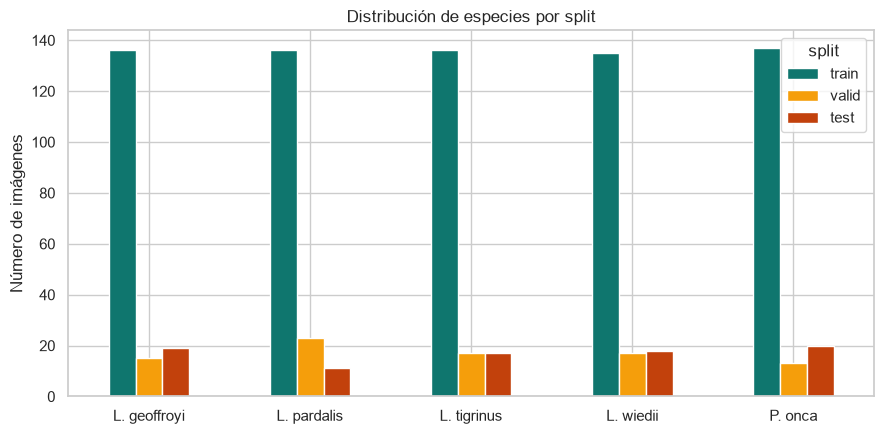

train: min=135  max=137  razón max/min = 1.01
valid: min= 13  max= 23  razón max/min = 1.77
test : min= 11  max= 20  razón max/min = 1.82


In [5]:
conteo = pd.crosstab(df["especie"].map(NOMBRES), df["split"])[["train", "valid", "test"]]
conteo.loc["Total"] = conteo.sum()
display(conteo)

ax = pd.crosstab(df["especie"].map(NOMBRES), df["split"])[["train", "valid", "test"]].plot(
    kind="bar", figsize=(9, 4.5), rot=0, color=["#0f766e", "#f59e0b", "#c2410c"])
ax.set_xlabel("")
ax.set_ylabel("Número de imágenes")
ax.set_title("Distribución de especies por split")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_distribucion_clases.png", dpi=150)
plt.show()

for s in ["train", "valid", "test"]:
    c = df[df.split == s]["especie"].value_counts()
    print(f"{s:5s}: min={c.min():3d}  max={c.max():3d}  razón max/min = {c.max() / c.min():.2f}")

### 3.2 Grid de imágenes por especie

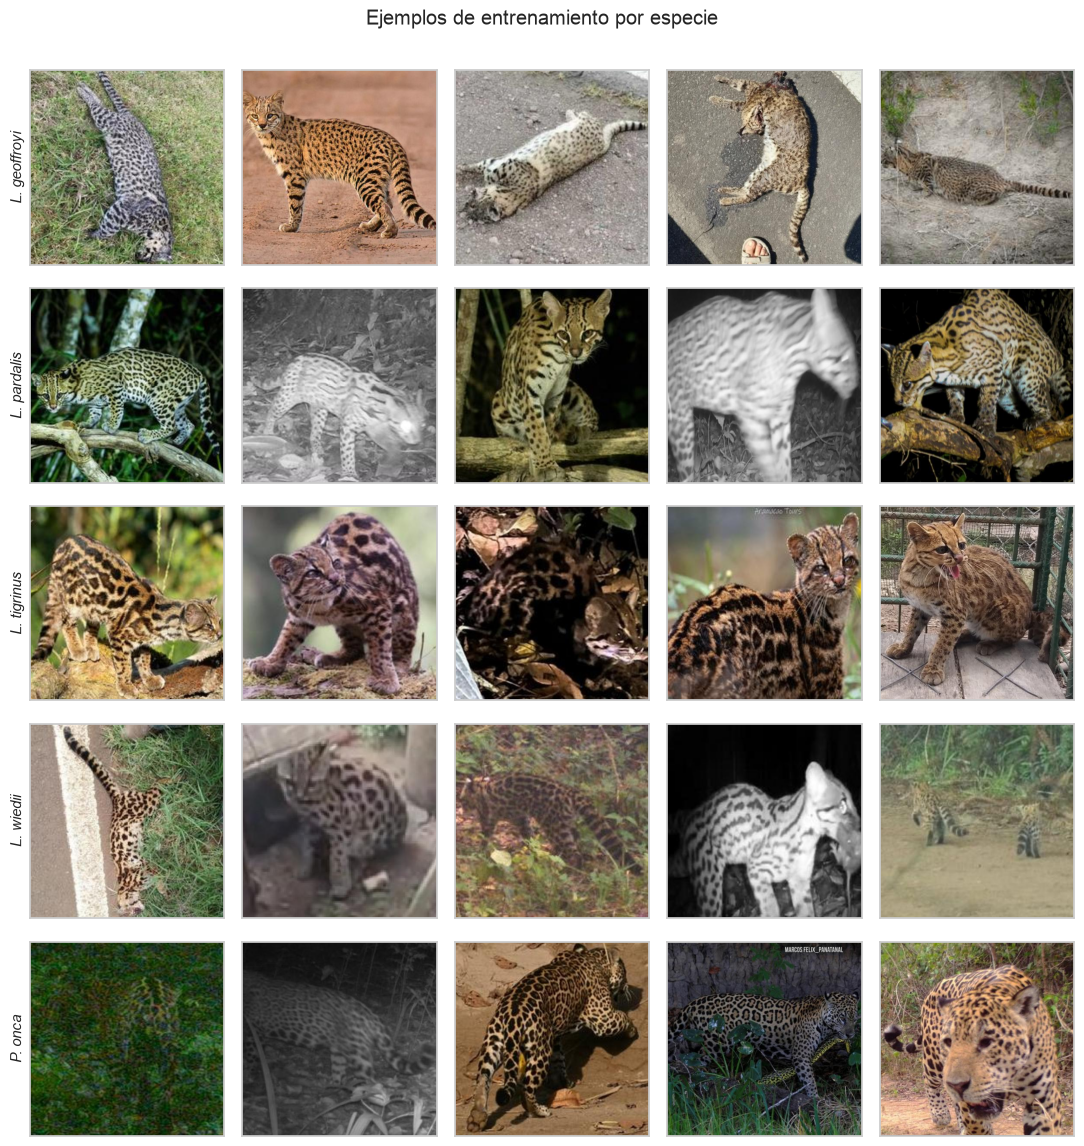

In [6]:
n = 5
fig, axes = plt.subplots(len(CLASES), n, figsize=(2.2 * n, 2.3 * len(CLASES)))
rng = np.random.default_rng(SEED)
for i, c in enumerate(CLASES):
    rutas = df[(df.especie == c) & (df.split == "train")]["ruta"].to_numpy()
    for j, r in enumerate(rng.choice(rutas, n, replace=False)):
        ax = axes[i, j]
        ax.imshow(Image.open(r))
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(NOMBRES[c], fontsize=11, style="italic")
plt.suptitle("Ejemplos de entrenamiento por especie", y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_grid_imagenes.png", dpi=120)
plt.show()

### 3.3 Resolución de las imágenes (H × W)

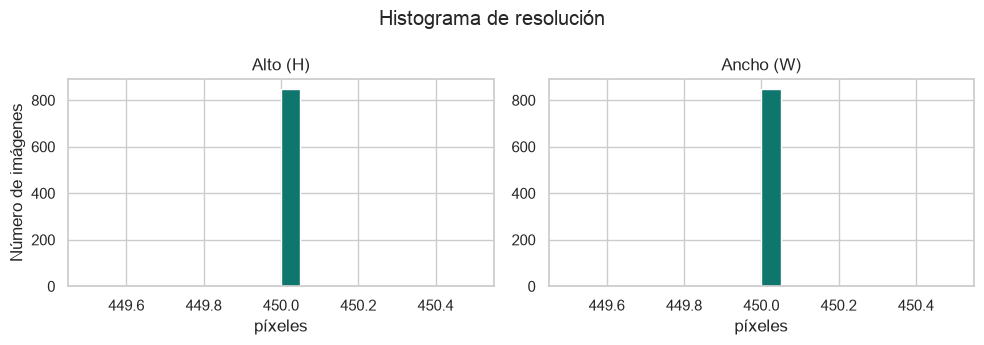

H    W  
450  450    850
Name: imágenes, dtype: int64


In [7]:
tamanos = np.array([Image.open(r).size for r in df["ruta"]])  # (W, H)
df["W"], df["H"] = tamanos[:, 0], tamanos[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df["H"], bins=20, color="#0f766e"); axes[0].set_title("Alto (H)"); axes[0].set_xlabel("píxeles")
axes[1].hist(df["W"], bins=20, color="#0f766e"); axes[1].set_title("Ancho (W)"); axes[1].set_xlabel("píxeles")
axes[0].set_ylabel("Número de imágenes")
plt.suptitle("Histograma de resolución")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_resolucion.png", dpi=150)
plt.show()

print(df.groupby(["H", "W"]).size().rename("imágenes"))

### 3.4 ¿Está normalizada? Intensidad de los píxeles

Media por canal (R, G, B): [0.442 0.426 0.375]
Std   por canal (R, G, B): [0.234 0.225 0.222]
Rango: 0.0 a 1.0
Referencia ImageNet  media: [0.485, 0.456, 0.406]  std: [0.229, 0.224, 0.225]


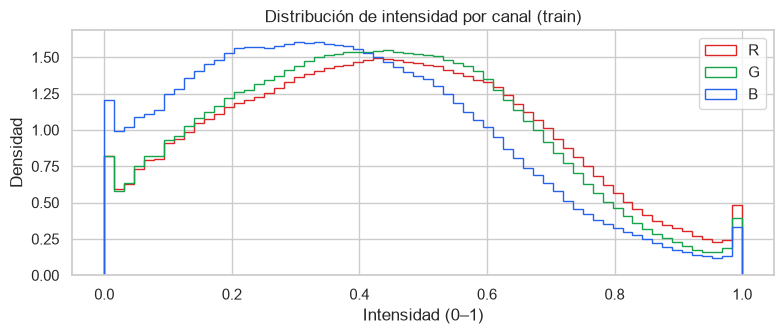

In [8]:
def arreglo(ruta, lado=112):
    """Imagen RGB reducida, en [0, 1]. Se reduce solo para acelerar las estadísticas."""
    return np.asarray(Image.open(ruta).convert("RGB").resize((lado, lado)), dtype=np.float32) / 255.0

train = df[df.split == "train"]
pix = np.stack([arreglo(r) for r in train["ruta"]])          # (N, 112, 112, 3)
media, std = pix.mean(axis=(0, 1, 2)), pix.std(axis=(0, 1, 2))
print("Media por canal (R, G, B):", media.round(3))
print("Std   por canal (R, G, B):", std.round(3))
print("Rango:", pix.min(), "a", pix.max())
print("Referencia ImageNet  media:", [0.485, 0.456, 0.406], " std:", [0.229, 0.224, 0.225])

fig, ax = plt.subplots(figsize=(8, 3.5))
for k, (canal, color) in enumerate(zip("RGB", ["#dc2626", "#16a34a", "#2563eb"])):
    ax.hist(pix[..., k].ravel(), bins=64, histtype="step", color=color, label=canal, density=True)
ax.set_xlabel("Intensidad (0–1)"); ax.set_ylabel("Densidad"); ax.legend()
ax.set_title("Distribución de intensidad por canal (train)")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_intensidad_canales.png", dpi=150)
plt.show()

### 3.5 ¿Cuántas fotos son realmente a color?

Muchas fotos de cámaras trampa nocturnas se toman con infrarrojo y salen en escala de grises aunque el archivo sea RGB. Se mide la diferencia media entre canales: si es casi 0, la foto es efectivamente gris. Esto es relevante para el experimento de color vs. escala de grises.

es_gris,color,gris (IR),Total
especie,,,
L. geoffroyi,135,35,170
L. pardalis,83,87,170
L. tigrinus,128,42,170
L. wiedii,88,82,170
P. onca,142,28,170
Total,576,274,850


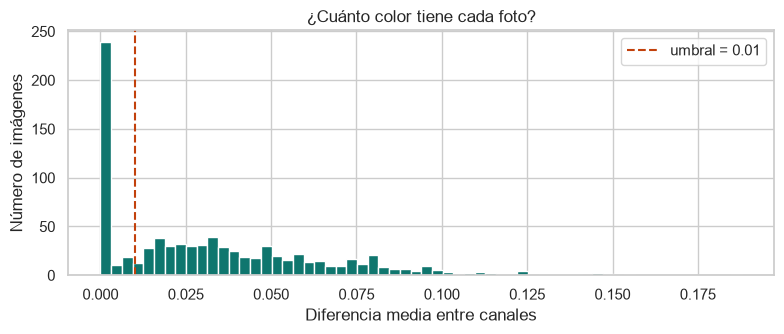

In [9]:
def colorido(ruta):
    a = arreglo(ruta, 64)
    return float(np.abs(a - a.mean(axis=2, keepdims=True)).mean())

df["colorido"] = [colorido(r) for r in df["ruta"]]
UMBRAL_GRIS = 0.01
df["es_gris"] = df["colorido"] < UMBRAL_GRIS

display(pd.crosstab(df["especie"].map(NOMBRES), df["es_gris"].map({True: "gris (IR)", False: "color"}),
                    margins=True, margins_name="Total"))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df["colorido"], bins=60, color="#0f766e")
ax.axvline(UMBRAL_GRIS, color="#c2410c", ls="--", label=f"umbral = {UMBRAL_GRIS}")
ax.set_xlabel("Diferencia media entre canales"); ax.set_ylabel("Número de imágenes"); ax.legend()
ax.set_title("¿Cuánto color tiene cada foto?")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_colorido.png", dpi=150)
plt.show()

### 3.6 Fuga de datos entre splits

Se verifica que no haya imágenes idénticas (mismo hash MD5) repetidas dentro o entre splits.

In [10]:
df["md5"] = [hashlib.md5(Path(r).read_bytes()).hexdigest() for r in df["ruta"]]
dup = df[df.duplicated("md5", keep=False)]
print("Imágenes con hash repetido:", len(dup))

Imágenes con hash repetido: 0


### 3.7 Estacionalidad y skewness

- **Estacionalidad:** no aplica; los datos no son series de tiempo.
- **Skewness / transformaciones no lineales:** no aplica a los píxeles de forma directa. Las imágenes se normalizan con la media y la desviación estándar de ImageNet antes de entrar a la ResNet50, que es la normalización con la que fue preentrenada.

### 3.8 Conclusiones del EDA

1. **Balance:** train está balanceado (135–137 por especie, razón máx/mín 1.01). Valid y test no tanto (11–23 por especie, razón ~1.8), por eso la métrica principal es **F1 macro**.
2. **Resolución:** las 850 imágenes miden 450×450, porque Roboflow las redimensionó con *stretch*. El histograma tiene un único valor y se pierde la relación de aspecto original.
3. **Normalización:** los píxeles están en [0, 1] con media (0.44, 0.43, 0.38) y desviación (~0.23) por canal, cerca de los valores de ImageNet. Antes de la ResNet50 se normalizan con la media/std de ImageNet.
4. **Fotos infrarrojas:** **274 de 850 (32 %)** son efectivamente grises (cámaras trampa nocturnas), y el reparto no es parejo: ~51 % en *L. pardalis* y ~48 % en *L. wiedii*, contra ~16 % en *P. onca*. El modelo podría usar "es foto nocturna" como pista. Se tendrá en cuenta al interpretar resultados y en el experimento de color.
5. **Fuentes variadas:** hay fotos de cámaras trampa, de zoológico, animales atropellados y algunas con marcas de agua. Es un dataset heterogéneo.
6. **Fuga de datos:** no hay imágenes duplicadas (MD5) dentro ni entre splits.

## 4. Extracción de características (transfer learning)

Se usa **ResNet50** [3] preentrenada en ImageNet [4] (pesos de torchvision / PyTorch [9]) como extractor fijo: se reemplaza la última capa (`fc`) por la identidad, así la salida es el vector de 2048 dimensiones del *global average pooling*. La red no se reentrena.

Los embeddings se calculan una vez y se guardan en `outputs/embeddings/`.

In [11]:
import torchvision
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

IMAGENET_MEDIA, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

def transformacion(gris: bool = False):
    pasos = [transforms.Resize((224, 224))]
    if gris:  # para el experimento de color: gris replicado en 3 canales
        pasos.append(transforms.Grayscale(num_output_channels=3))
    pasos += [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEDIA, IMAGENET_STD)]
    return transforms.Compose(pasos)

class Imagenes(Dataset):
    def __init__(self, rutas, tf):
        self.rutas, self.tf = list(rutas), tf
    def __len__(self):
        return len(self.rutas)
    def __getitem__(self, i):
        return self.tf(Image.open(self.rutas[i]).convert("RGB"))

def resnet50_extractor():
    m = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
    m.fc = torch.nn.Identity()
    return m.eval().to(DEVICE)

@torch.no_grad()
def extraer(modelo, rutas, tf, batch=32):
    dl = DataLoader(Imagenes(rutas, tf), batch_size=batch, shuffle=False)
    return np.concatenate([modelo(x.to(DEVICE)).cpu().numpy() for x in dl]).astype(np.float32)

def embeddings(nombre, gris=False):
    archivo = EMB_DIR / f"{nombre}.npy"
    if archivo.exists():
        return np.load(archivo)
    t0 = time.time()
    X = extraer(resnet50_extractor(), df["ruta"], transformacion(gris))
    np.save(archivo, X)
    print(f"{nombre}: {X.shape} en {time.time() - t0:.1f} s")
    return X

X_todo = embeddings("resnet50_color")
print(X_todo.shape)

(850, 2048)


### Conjuntos de desarrollo y test

- **Desarrollo = train + valid (765)**: sobre este conjunto se hace toda la validación cruzada.
- **Test (85)**: se aparta y se usa una sola vez, al final.

In [12]:
es_dev = df["split"].isin(["train", "valid"]).to_numpy()
X_dev, y_dev = X_todo[es_dev], df.loc[es_dev, "y"].to_numpy()
X_test, y_test = X_todo[~es_dev], df.loc[~es_dev, "y"].to_numpy()
print("Desarrollo:", X_dev.shape, "| Test:", X_test.shape)
print("Clases en desarrollo:", np.bincount(y_dev), "| en test:", np.bincount(y_test))

Desarrollo: (765, 2048) | Test: (85, 2048)
Clases en desarrollo: [151 159 153 152 150] | en test: [19 11 17 18 20]


## 5. Feature selection

Se **omite**, como permite la rúbrica cuando se usa transfer learning con imágenes. Las 2048 características son representaciones densas aprendidas por la red, no variables originales con significado individual que convenga filtrar. Seleccionarlas con un filtro univariado descartaría información que los modelos sí pueden aprovechar en conjunto.

## 6. Pipelines

Todo el preprocesamiento que aprende de los datos (aquí, el `StandardScaler`) vive **dentro** de un `Pipeline` de scikit-learn [5]. Así se ajusta solo con los datos de entrenamiento de cada fold y no hay fuga de información del fold de validación. El mismo pipeline se usa en la optimización, la comparación estadística y la evaluación final.

- **SVM (kernel RBF)** [6]: busca la frontera de máximo margen entre clases en el espacio transformado por el kernel. Es sensible a la escala, por eso el `StandardScaler`.
- **Random Forest** [7]: ensamble de árboles de decisión entrenados con muestras y subconjuntos de características aleatorios. No necesita escalar, pero se usa el mismo pipeline para que la comparación sea justa.

In [13]:
import json, warnings
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, GridSearchCV, learning_curve

def pipeline(clf):
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])

def pipeline_svm(**params):
    return pipeline(SVC(kernel="rbf", probability=True, random_state=SEED, **params))

def pipeline_rf(**params):
    return pipeline(RandomForestClassifier(random_state=SEED, n_jobs=1, **params))

# Validación cruzada: 10 folds × 10 repeticiones, estratificada, misma semilla para todo el proyecto
CV = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=SEED)
METRICA = "f1_macro"

CV_DIR = RAIZ / "outputs" / "cv"
CV_DIR.mkdir(parents=True, exist_ok=True)
pipeline_svm()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samp

## 7. Optimización de hiperparámetros

Búsqueda en grilla (`GridSearchCV`) con **repeated stratified k-fold 10×10** sobre el conjunto de desarrollo (765 imágenes), maximizando **F1 macro**. No se usa nested CV (lo desaconseja la rúbrica por su costo). El test no se toca.

| Modelo | Hiperparámetro | Valores | Por qué |
| --- | --- | --- | --- |
| SVM | `C` | 10⁻³ … 10³ (7 valores, escala log) | Penalización del error: bajo = margen ancho (más sesgo), alto = ajusta más al train (más varianza). Su efecto es multiplicativo, por eso escala log. |
| SVM | `gamma` | `"scale"`, 10⁻⁵ … 10⁻¹ | Alcance del kernel RBF: bajo = frontera suave, alto = frontera muy local. `"scale"` = 1 / (n_features · var(X)). |
| RF | `n_estimators` | 100, 300, 500 | Más árboles = predicción más estable, con rendimientos decrecientes. |
| RF | `max_depth` | None, 10, 20, 40 | Limitar la profundidad reduce el sobreajuste. |
| RF | `max_features` | `"sqrt"`, `"log2"`, 0.1 | Características candidatas en cada división: menos = árboles más distintos entre sí. |

Los resultados se guardan en `outputs/cv/` para no repetir la búsqueda cada vez que se corre la notebook.

In [14]:
def buscar(nombre, pipe, grilla, desempate=()):
    """GridSearchCV con caché en CSV. Devuelve (resultados ordenados, mejores parámetros)."""
    archivo = CV_DIR / f"grid_{nombre}.csv"
    if archivo.exists():
        res = pd.read_csv(archivo)
    else:
        t0 = time.time()
        gs = GridSearchCV(pipe, grilla, cv=CV, scoring=METRICA, n_jobs=-1, refit=False)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            gs.fit(X_dev, y_dev)
        res = pd.DataFrame(gs.cv_results_)
        res["params"] = [json.dumps(p) for p in res["params"]]
        res = res.drop(columns=[c for c in res.columns if c.startswith("split")])
        res.to_csv(archivo, index=False)
        print(f"{nombre}: {len(res)} combinaciones × {CV.get_n_splits()} folds en {(time.time() - t0) / 60:.1f} min")
    # Ranking por F1 medio. Ante empates (misma media a 4 decimales) se elige el modelo más simple,
    # según el orden de `desempate` (p. ej. menor C, árboles menos profundos, menos árboles).
    res["_media"] = res["mean_test_score"].round(4)
    claves = ["_media"] + [f"_d{i}" for i in range(len(desempate))]
    for i, col in enumerate(desempate):
        res[f"_d{i}"] = res[f"param_clf__{col}"].fillna(np.inf).astype(float)
    res = res.sort_values(claves, ascending=[False] + [True] * len(desempate)).drop(columns=claves)
    mejor = {k.replace("clf__", ""): v for k, v in json.loads(res.iloc[0]["params"]).items()}
    return res, mejor

def tabla_top(res, n=5):
    cols = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
    return res[cols].head(n).rename(columns=lambda c: c.replace("param_clf__", "")).round(4)

### 7.1 SVM

In [15]:
grilla_svm = {
    "clf__C": np.logspace(-3, 3, 7).tolist(),
    "clf__gamma": ["scale"] + np.logspace(-5, -1, 5).tolist(),
}
# probability=False durante la búsqueda (solo se necesita F1, y es ~5× más rápido)
res_svm, mejor_svm = buscar("svm", pipeline(SVC(kernel="rbf", random_state=SEED)), grilla_svm,
                            desempate=["C"])
print("Mejores hiperparámetros SVM:", mejor_svm)
tabla_top(res_svm)

Mejores hiperparámetros SVM: {'C': 100.0, 'gamma': 0.0001}


,C,gamma,mean_test_score,std_test_score
32,100.0,0.0001,0.7755,0.0398
38,1000.0,0.0001,0.7755,0.0398
26,10.0,0.0001,0.7736,0.0432
37,1000.0,1e-05,0.7717,0.0414
31,100.0,1e-05,0.7704,0.0441


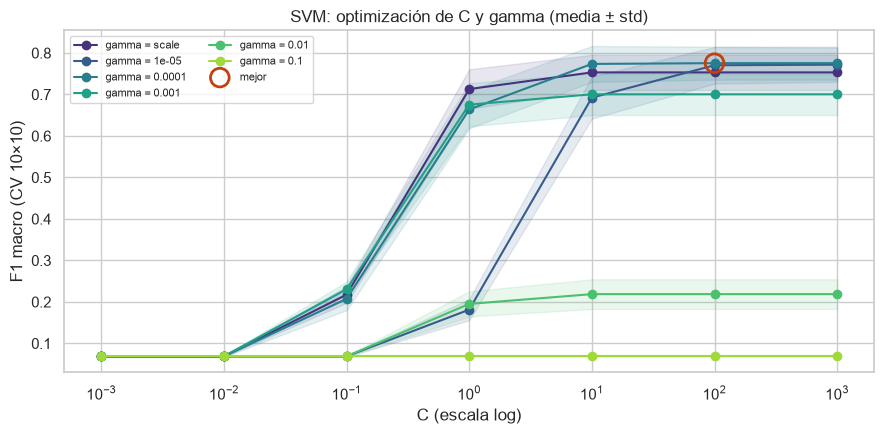

In [16]:
# Gráfica de optimización: F1 macro vs. C, una curva por gamma
fig, ax = plt.subplots(figsize=(9, 4.5))
gammas = res_svm["param_clf__gamma"].astype(str).unique()
paleta = sns.color_palette("viridis", len(gammas))
for g, color in zip(sorted(gammas, key=lambda v: (v != "scale", float(v) if v != "scale" else 0)), paleta):
    sub = res_svm[res_svm["param_clf__gamma"].astype(str) == g].sort_values("param_clf__C")
    C = sub["param_clf__C"].astype(float)
    ax.plot(C, sub["mean_test_score"], marker="o", color=color, label=f"gamma = {g}")
    ax.fill_between(C, sub["mean_test_score"] - sub["std_test_score"],
                    sub["mean_test_score"] + sub["std_test_score"], color=color, alpha=0.12)
mejor_fila = res_svm.iloc[0]
ax.scatter([float(mejor_fila["param_clf__C"])], [mejor_fila["mean_test_score"]], s=180,
           facecolors="none", edgecolors="#c2410c", linewidths=2, zorder=5, label="mejor")
ax.set_xscale("log")
ax.set_xlabel("C (escala log)")
ax.set_ylabel("F1 macro (CV 10×10)")
ax.set_title("SVM: optimización de C y gamma (media ± std)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(FIG_DIR / "opt_svm_C_gamma.png", dpi=150)
plt.show()

### 7.2 Random Forest

In [17]:
grilla_rf = {
    "clf__n_estimators": [100, 300, 500],
    "clf__max_depth": [None, 10, 20, 40],
    "clf__max_features": ["sqrt", "log2", 0.1],
}
res_rf, mejor_rf = buscar("rf", pipeline_rf(), grilla_rf,
                          desempate=["max_depth", "n_estimators"])
print("Mejores hiperparámetros RF:", mejor_rf)
tabla_top(res_rf)

Mejores hiperparámetros RF: {'max_depth': 20, 'max_features': 0.1, 'n_estimators': 500}


,max_depth,max_features,n_estimators,mean_test_score,std_test_score
26,20.0,0.1,500,0.7097,0.0472
35,40.0,0.1,500,0.7097,0.0472
8,NaN,0.1,500,0.7097,0.0472
25,20.0,0.1,300,0.7074,0.0519
34,40.0,0.1,300,0.7074,0.0519


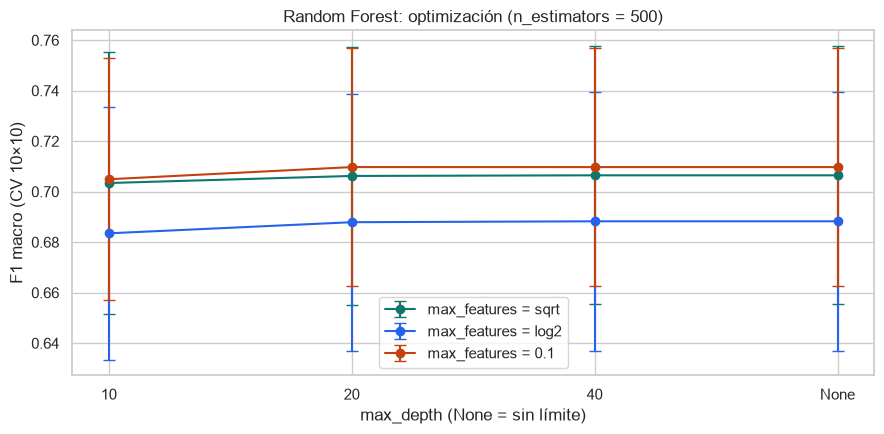

,param_clf__n_estimators,mean_test_score,std_test_score
24,100,0.6917,0.0529
25,300,0.7074,0.0519
26,500,0.7097,0.0472


In [18]:
# Gráfica de optimización: F1 macro vs. max_depth, una curva por max_features (con el mejor n_estimators)
r = res_rf[res_rf["param_clf__n_estimators"] == mejor_rf["n_estimators"]].copy()
r["prof"] = r["param_clf__max_depth"].astype(object).fillna("None").astype(str).str.replace(".0", "", regex=False)
orden = ["10", "20", "40", "None"]
fig, ax = plt.subplots(figsize=(9, 4.5))
for mf, color in zip(["sqrt", "log2", "0.1"], ["#0f766e", "#2563eb", "#c2410c"]):
    sub = r[r["param_clf__max_features"].astype(str) == mf].set_index("prof").loc[orden]
    ax.errorbar(orden, sub["mean_test_score"], yerr=sub["std_test_score"], marker="o",
                capsize=4, color=color, label=f"max_features = {mf}")
ax.set_xlabel("max_depth (None = sin límite)")
ax.set_ylabel("F1 macro (CV 10×10)")
ax.set_title(f"Random Forest: optimización (n_estimators = {mejor_rf['n_estimators']})")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "opt_rf_depth_features.png", dpi=150)
plt.show()

# Efecto de n_estimators con el resto de hiperparámetros en su mejor valor
r2 = res_rf[(res_rf["param_clf__max_features"].astype(str) == str(mejor_rf["max_features"])) &
            (res_rf["param_clf__max_depth"].fillna(-1) == (mejor_rf["max_depth"] if mejor_rf["max_depth"] is not None else -1))]
display(r2[["param_clf__n_estimators", "mean_test_score", "std_test_score"]].sort_values("param_clf__n_estimators").round(4))

### 7.3 Curvas de aprendizaje

Score de entrenamiento y de validación según el tamaño del conjunto de entrenamiento, con los mejores hiperparámetros y el mismo CV 10×10. Sirven para diagnosticar sesgo y varianza:
- Si las dos curvas convergen en un score bajo → **sesgo alto** (el modelo no alcanza).
- Si hay una brecha grande entre train y validación → **varianza alta** (sobreajuste); más datos ayudarían.

SVM: F1 train = 1.000 | F1 validación = 0.776 | brecha = 0.224
Random Forest: F1 train = 1.000 | F1 validación = 0.710 | brecha = 0.290


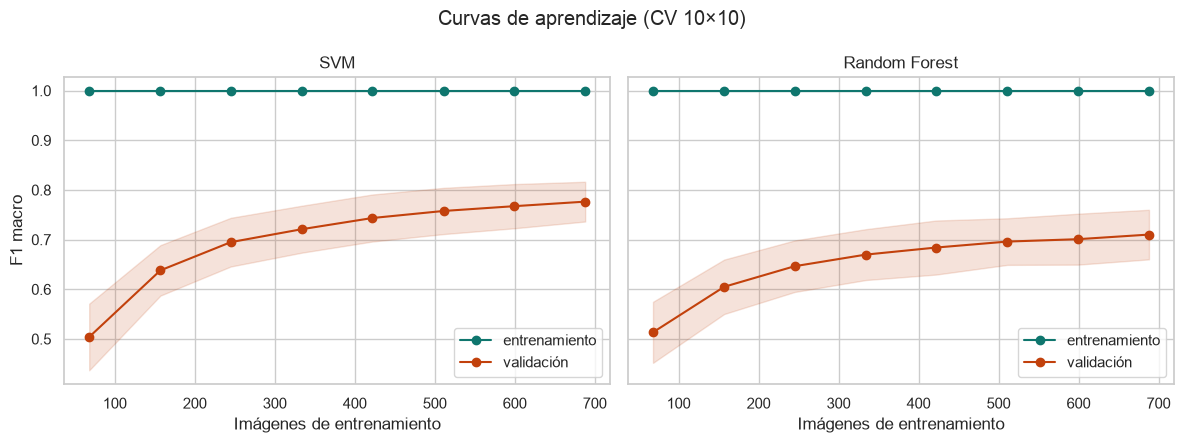

In [19]:
def curva_aprendizaje(nombre, pipe, params):
    # la caché depende de los hiperparámetros: si cambian, se recalcula
    clave = hashlib.md5(json.dumps(params, sort_keys=True).encode()).hexdigest()[:8]
    archivo = CV_DIR / f"lc_{nombre}_{clave}.npz"
    if archivo.exists():
        d = np.load(archivo)
        return d["tam"], d["tr"], d["va"]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        tam, tr, va = learning_curve(pipe, X_dev, y_dev, cv=CV, scoring=METRICA, n_jobs=-1,
                                     train_sizes=np.linspace(0.1, 1.0, 8), shuffle=True, random_state=SEED)
    np.savez(archivo, tam=tam, tr=tr, va=va)
    return tam, tr, va

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (nombre, clave, pipe, params) in zip(axes, [
        ("SVM", "svm", pipeline(SVC(kernel="rbf", random_state=SEED, **mejor_svm)), mejor_svm),
        ("Random Forest", "rf", pipeline_rf(**mejor_rf), mejor_rf)]):
    tam, tr, va = curva_aprendizaje(clave, pipe, params)
    for s, color, et in [(tr, "#0f766e", "entrenamiento"), (va, "#c2410c", "validación")]:
        ax.plot(tam, s.mean(1), marker="o", color=color, label=et)
        ax.fill_between(tam, s.mean(1) - s.std(1), s.mean(1) + s.std(1), color=color, alpha=0.15)
    ax.set_title(f"{nombre}")
    ax.set_xlabel("Imágenes de entrenamiento")
    ax.legend(loc="lower right")
    print(f"{nombre}: F1 train = {tr.mean(1)[-1]:.3f} | F1 validación = {va.mean(1)[-1]:.3f} "
          f"| brecha = {tr.mean(1)[-1] - va.mean(1)[-1]:.3f}")
axes[0].set_ylabel("F1 macro")
plt.suptitle("Curvas de aprendizaje (CV 10×10)")
plt.tight_layout()
plt.savefig(FIG_DIR / "curvas_aprendizaje.png", dpi=150)
plt.show()

### 7.4 Extra: optimización del SVM con Optuna

Optuna [11] explora `C` y `gamma` como valores continuos (escala log) con un muestreador bayesiano (TPE), en lugar de una grilla fija. Se usa el mismo CV 10×10 para comparar con la grilla.

Optuna  : F1 = 0.7800  (C = 21.59, gamma = 0.0001384)
Grilla  : F1 = 0.7755  {'C': 100.0, 'gamma': 0.0001}


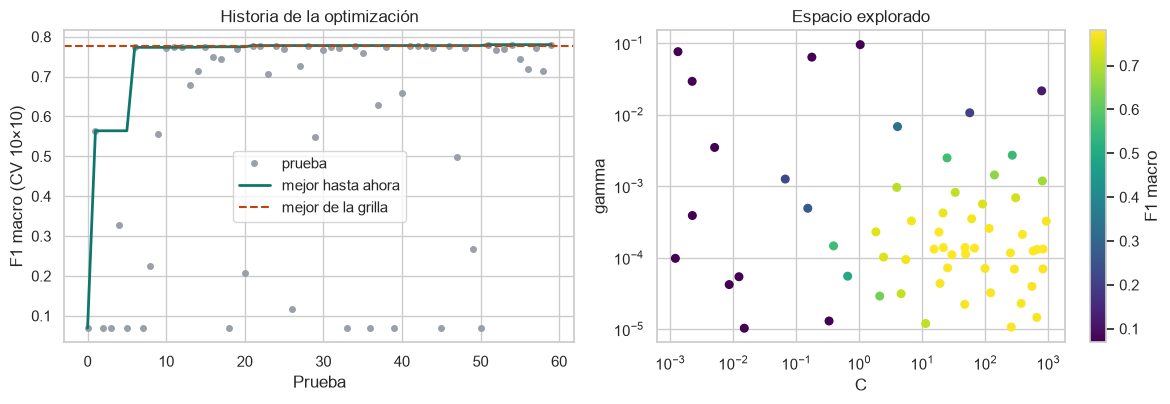

In [20]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # aviso de tqdm sin ipywidgets
    import optuna
from sklearn.model_selection import cross_val_score
optuna.logging.set_verbosity(optuna.logging.WARNING)

archivo_optuna = CV_DIR / "optuna_svm.csv"
if archivo_optuna.exists():
    hist = pd.read_csv(archivo_optuna)
else:
    def objetivo(trial):
        C = trial.suggest_float("C", 1e-3, 1e3, log=True)
        gamma = trial.suggest_float("gamma", 1e-5, 1e-1, log=True)
        return cross_val_score(pipeline(SVC(kernel="rbf", C=C, gamma=gamma, random_state=SEED)),
                               X_dev, y_dev, cv=CV, scoring=METRICA, n_jobs=-1).mean()
    estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    t0 = time.time()
    estudio.optimize(objetivo, n_trials=60)
    print(f"Optuna: 60 pruebas en {(time.time() - t0) / 60:.1f} min")
    hist = estudio.trials_dataframe()[["number", "value", "params_C", "params_gamma"]]
    hist.to_csv(archivo_optuna, index=False)

mejor_optuna = hist.loc[hist["value"].idxmax()]
print(f"Optuna  : F1 = {mejor_optuna['value']:.4f}  (C = {mejor_optuna['params_C']:.4g}, gamma = {mejor_optuna['params_gamma']:.4g})")
print(f"Grilla  : F1 = {res_svm.iloc[0]['mean_test_score']:.4f}  {mejor_svm}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(hist["number"], hist["value"], "o", color="#9aa0aa", ms=4, label="prueba")
axes[0].plot(hist["number"], hist["value"].cummax(), color="#0f766e", lw=2, label="mejor hasta ahora")
axes[0].axhline(res_svm.iloc[0]["mean_test_score"], color="#c2410c", ls="--", label="mejor de la grilla")
axes[0].set_xlabel("Prueba"); axes[0].set_ylabel("F1 macro (CV 10×10)"); axes[0].legend()
axes[0].set_title("Historia de la optimización")
sc = axes[1].scatter(hist["params_C"], hist["params_gamma"], c=hist["value"], cmap="viridis", s=30)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("C"); axes[1].set_ylabel("gamma"); axes[1].set_title("Espacio explorado")
plt.colorbar(sc, ax=axes[1], label="F1 macro")
plt.tight_layout()
plt.savefig(FIG_DIR / "opt_svm_optuna.png", dpi=150)
plt.show()

### 7.5 Conclusiones de la optimización

| Modelo | Mejores hiperparámetros | F1 macro (CV 10×10) |
| --- | --- | --- |
| SVM (grilla) | `C = 100`, `gamma = 1e-4` | **0.776 ± 0.040** |
| SVM (Optuna) | `C ≈ 21.6`, `gamma ≈ 1.4e-4` | 0.780 |
| Random Forest | `n_estimators = 500`, `max_depth = 20`, `max_features = 0.1` | **0.710 ± 0.047** |

1. **SVM:** `gamma` es el hiperparámetro decisivo. Con valores grandes (0.01–0.1) el kernel es tan local que el modelo colapsa a predecir casi una sola clase (F1 ≈ 0.07–0.22). Con `gamma ≈ 1e-4` y `C ≥ 10` se alcanza una meseta. El mejor `C` está en el borde de la grilla, pero la curva ya es plana: `C = 100` y `C = 1000` dan el mismo F1. Ante empates se elige el modelo más simple (menor `C`).
2. **Random Forest:** la profundidad casi no influye a partir de 20, y `max_features = 0.1` es ligeramente mejor que `sqrt` y `log2`. Pasar de 100 a 500 árboles mejora el F1 en ~0.02.
3. **Optuna** llega a 0.780 frente a 0.776 de la grilla, una diferencia muy inferior a la desviación estándar (~0.04): la grilla ya había encontrado la región óptima.
4. **Curvas de aprendizaje:** ambos modelos obtienen F1 = 1.0 en entrenamiento y la curva de validación sigue subiendo al agregar imágenes. Es un caso de **varianza alta**: el modelo se beneficiaría de más datos. El SVM supera al RF en todos los tamaños de entrenamiento.


## 8. Comparación estadística: SVM vs. Random Forest

Se comparan los dos modelos optimizados con el **mismo** `RepeatedStratifiedKFold` 10×10 (misma semilla), así cada fold produce un par de scores (SVM, RF) calculados sobre exactamente los mismos datos. Se obtienen 100 pares por métrica.

**Métricas** (las que pide la rúbrica para clasificación): accuracy, precision y recall (macro), F1 macro y F1 weighted, AUC ROC macro y micro (one-vs-rest).

In [21]:
from sklearn.model_selection import cross_validate, cross_val_predict, StratifiedKFold
from sklearn.metrics import make_scorer, roc_auc_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
from scipy import stats

def auc_micro(y_true, y_proba):
    return roc_auc_score(label_binarize(y_true, classes=range(len(CLASES))), y_proba, average="micro")

METRICAS = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted",
    "auc_macro": "roc_auc_ovr",
    "auc_micro": make_scorer(auc_micro, response_method="predict_proba"),
}

MODELOS = {
    "SVM": pipeline_svm(**mejor_svm),   # probability=True: necesario para AUC/ROC
    "Random Forest": pipeline_rf(**mejor_rf),
}

archivo_comp = CV_DIR / "comparacion_10x10.csv"
if archivo_comp.exists():
    scores = pd.read_csv(archivo_comp)
else:
    filas = []
    for nombre, pipe in MODELOS.items():
        t0 = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            r = cross_validate(pipe, X_dev, y_dev, cv=CV, scoring=METRICAS, n_jobs=-1)
        print(f"{nombre}: {CV.get_n_splits()} folds en {(time.time() - t0) / 60:.1f} min")
        for k in range(CV.get_n_splits()):
            filas.append({"modelo": nombre, "fold": k, **{m: r[f"test_{m}"][k] for m in METRICAS}})
    scores = pd.DataFrame(filas)
    scores.to_csv(archivo_comp, index=False)

resumen = scores.groupby("modelo")[list(METRICAS)].agg(["mean", "std"])
tabla = pd.DataFrame({m: [f"{resumen.loc[mod, (m, 'mean')]:.3f} ± {resumen.loc[mod, (m, 'std')]:.3f}"
                          for mod in MODELOS] for m in METRICAS}, index=list(MODELOS)).T
tabla.index.name = "métrica (CV 10×10)"
tabla

,SVM,Random Forest
métrica (CV 10×10),,
accuracy,0.775 ± 0.040,0.712 ± 0.046
precision_macro,0.787 ± 0.040,0.719 ± 0.048
recall_macro,0.776 ± 0.040,0.713 ± 0.046
f1_macro,0.775 ± 0.040,0.710 ± 0.047
f1_weighted,0.774 ± 0.040,0.708 ± 0.048
auc_macro,0.949 ± 0.015,0.928 ± 0.017
auc_micro,0.956 ± 0.013,0.934 ± 0.016


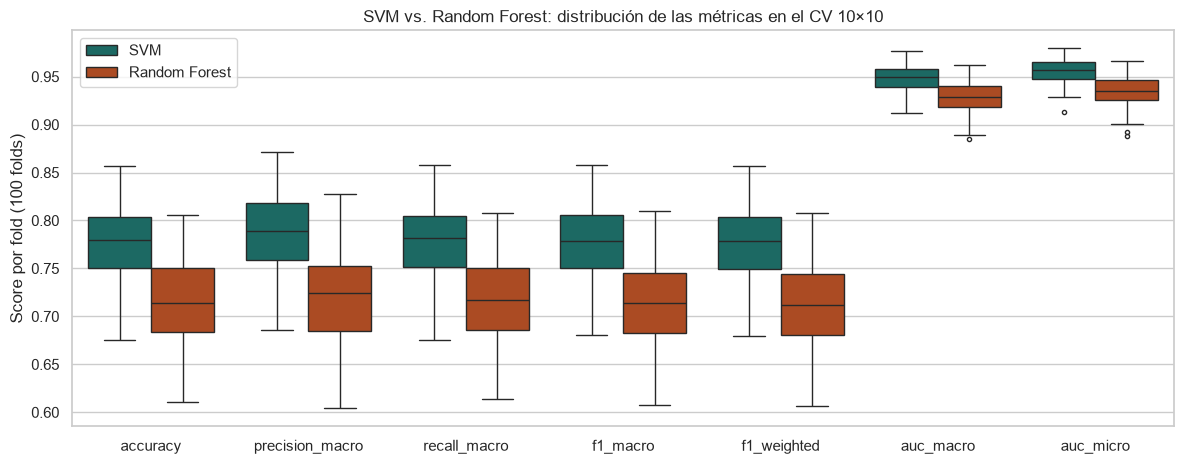

In [22]:
largo = scores.melt(id_vars=["modelo", "fold"], var_name="métrica", value_name="score")
fig, ax = plt.subplots(figsize=(12, 4.8))
sns.boxplot(data=largo, x="métrica", y="score", hue="modelo", palette=["#0f766e", "#c2410c"], ax=ax,
            flierprops={"marker": "o", "markersize": 3})
ax.set_xlabel("")
ax.set_ylabel("Score por fold (100 folds)")
ax.set_title("SVM vs. Random Forest: distribución de las métricas en el CV 10×10")
ax.legend(title="")
plt.tight_layout()
plt.savefig(FIG_DIR / "comparacion_boxplot.png", dpi=150)
plt.show()

### 8.1 Test de hipótesis

- **H₀:** no hay diferencia en F1 macro entre SVM y Random Forest (la mediana de las diferencias por fold es 0).
- **H₁:** sí hay diferencia.
- **Nivel de significancia:** α = 0.05.

**Test elegido: Wilcoxon de rangos con signo (pareado)** [8]. Los scores están pareados (mismos folds) y el Wilcoxon no asume que las diferencias sean normales. Primero se verifica la normalidad de las diferencias con Shapiro–Wilk [12] para justificar la elección.

**Limitación conocida:** los 100 folds no son independientes (los conjuntos de entrenamiento se solapan), lo que hace que los tests clásicos sean optimistas (p-valores demasiado pequeños). Como chequeo de robustez se agrega el **t-test corregido de Nadeau y Bengio** [13], que infla la varianza para compensar ese solapamiento.

In [23]:
ALFA = 0.05
svm = scores[scores.modelo == "SVM"].sort_values("fold")
rf = scores[scores.modelo == "Random Forest"].sort_values("fold")

def t_corregido(d, n_train, n_test):
    """t-test de remuestreo corregido (Nadeau & Bengio, 2003)."""
    J = len(d)
    var = np.var(d, ddof=1)
    t = d.mean() / np.sqrt((1 / J + n_test / n_train) * var)
    return t, 2 * stats.t.sf(abs(t), df=J - 1)

n_test_fold = len(y_dev) // 10
n_train_fold = len(y_dev) - n_test_fold

filas = []
for m in METRICAS:
    d = svm[m].to_numpy() - rf[m].to_numpy()
    w = stats.wilcoxon(svm[m], rf[m])
    _, p_shapiro = stats.shapiro(d)
    _, p_corr = t_corregido(d, n_train_fold, n_test_fold)
    filas.append({"métrica": m, "SVM − RF (media)": d.mean(), "folds SVM gana": int((d > 0).sum()),
                  "Shapiro p (normalidad)": p_shapiro, "Wilcoxon W": w.statistic, "Wilcoxon p": w.pvalue,
                  "t corregido p": p_corr})
tests = pd.DataFrame(filas).set_index("métrica")
display(tests.style.format({"SVM − RF (media)": "{:+.3f}", "Shapiro p (normalidad)": "{:.3g}", "Wilcoxon W": "{:.0f}",
                            "Wilcoxon p": "{:.2e}", "t corregido p": "{:.2e}"}))

d = svm["f1_macro"].to_numpy() - rf["f1_macro"].to_numpy()
w = tests.loc["f1_macro"]
print(f"F1 macro — diferencia media SVM − RF = {d.mean():+.4f}; SVM gana en {int((d > 0).sum())} de 100 folds")
print(f"Shapiro–Wilk sobre las diferencias: p = {w['Shapiro p (normalidad)']:.3g}")
print(f"Wilcoxon: W = {w['Wilcoxon W']:.0f}, p = {w['Wilcoxon p']:.2e} → "
      f"{'se rechaza H0' if w['Wilcoxon p'] < ALFA else 'no se rechaza H0'} (α = {ALFA})")
print(f"t corregido (Nadeau–Bengio): p = {w['t corregido p']:.2e} → "
      f"{'se rechaza H0' if w['t corregido p'] < ALFA else 'no se rechaza H0'}")

,SVM − RF (media),folds SVM gana,Shapiro p (normalidad),Wilcoxon W,Wilcoxon p,t corregido p
métrica,,,,,,
accuracy,+0.063,92,0.103,50,8.12e-17,4.51e-05
precision_macro,+0.067,94,0.713,83,4.60e-17,4.53e-05
recall_macro,+0.063,95,0.23,66,4.16e-17,4.25e-05
f1_macro,+0.066,93,0.202,58,2.21e-17,3.40e-05
f1_weighted,+0.066,93,0.193,59,2.27e-17,3.42e-05
auc_macro,+0.021,96,0.755,41,1.33e-17,5.89e-06
auc_micro,+0.021,97,0.365,3,6.24e-18,2.96e-07


F1 macro — diferencia media SVM − RF = +0.0657; SVM gana en 93 de 100 folds
Shapiro–Wilk sobre las diferencias: p = 0.202
Wilcoxon: W = 58, p = 2.21e-17 → se rechaza H0 (α = 0.05)
t corregido (Nadeau–Bengio): p = 3.40e-05 → se rechaza H0


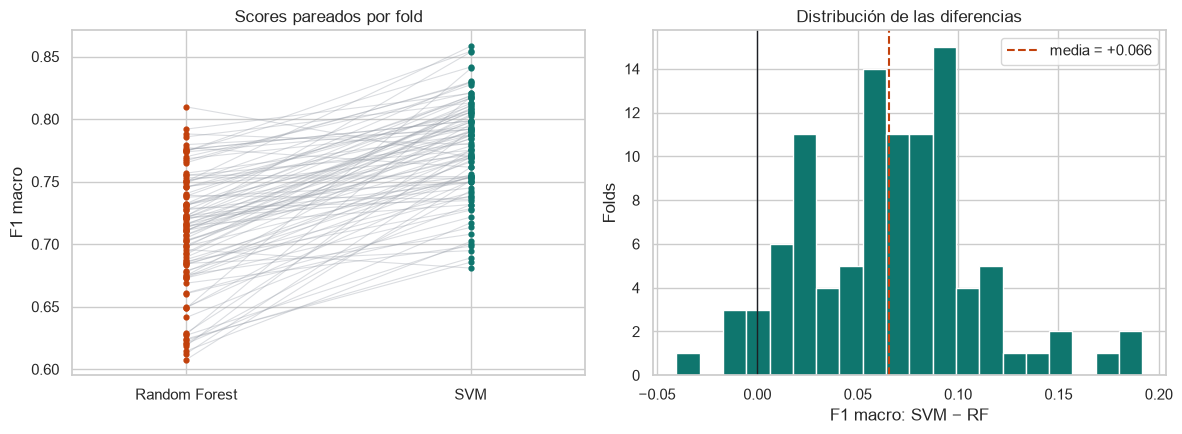

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
for k in range(len(svm)):
    ax.plot([0, 1], [rf["f1_macro"].iloc[k], svm["f1_macro"].iloc[k]], color="#9aa0aa", alpha=0.35, lw=0.8)
ax.scatter(np.zeros(len(rf)), rf["f1_macro"], color="#c2410c", s=12, zorder=3)
ax.scatter(np.ones(len(svm)), svm["f1_macro"], color="#0f766e", s=12, zorder=3)
ax.set_xticks([0, 1], ["Random Forest", "SVM"]); ax.set_xlim(-0.4, 1.4)
ax.set_ylabel("F1 macro"); ax.set_title("Scores pareados por fold")
ax = axes[1]
ax.hist(d, bins=20, color="#0f766e")
ax.axvline(0, color="#1d1f24", lw=1)
ax.axvline(d.mean(), color="#c2410c", ls="--", label=f"media = {d.mean():+.3f}")
ax.set_xlabel("F1 macro: SVM − RF"); ax.set_ylabel("Folds"); ax.legend()
ax.set_title("Distribución de las diferencias")
plt.tight_layout()
plt.savefig(FIG_DIR / "comparacion_pareada.png", dpi=150)
plt.show()

### 8.2 Curvas ROC (one-vs-rest)

Para dibujar las curvas se necesitan probabilidades de todas las imágenes de desarrollo. Se obtienen con `cross_val_predict` sobre un **único** 10-fold estratificado (cada imagen se predice una vez, con un modelo que no la vio). Se muestran la curva de cada especie y los promedios **micro** (todas las decisiones juntas) y **macro** (promedio de las curvas por especie).

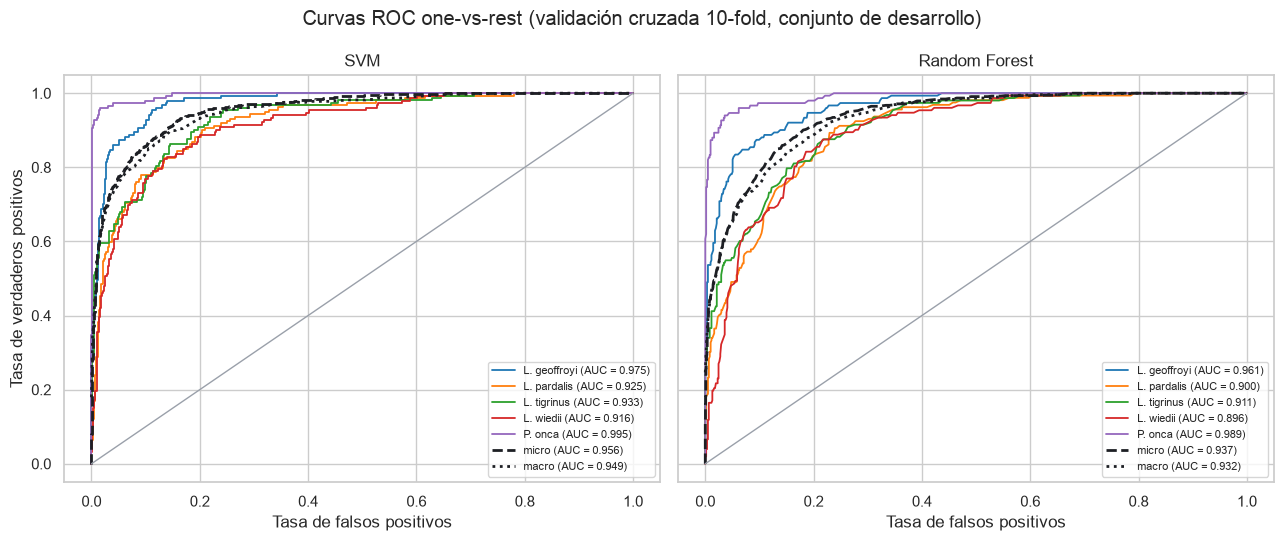

In [25]:
archivo_proba = CV_DIR / "proba_cv10.npz"
if archivo_proba.exists():
    proba = dict(np.load(archivo_proba))
else:
    cv1 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        proba = {n: cross_val_predict(p, X_dev, y_dev, cv=cv1, method="predict_proba", n_jobs=-1)
                 for n, p in MODELOS.items()}
    np.savez(archivo_proba, **proba)

Y = label_binarize(y_dev, classes=range(len(CLASES)))
grid_fpr = np.linspace(0, 1, 501)
colores = sns.color_palette("tab10", len(CLASES))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, nombre in zip(axes, MODELOS):
    P = proba[nombre]
    tprs = []
    for i, c in enumerate(CLASES):
        fpr, tpr, _ = roc_curve(Y[:, i], P[:, i])
        tprs.append(np.interp(grid_fpr, fpr, tpr))
        ax.plot(fpr, tpr, color=colores[i], lw=1.3, label=f"{NOMBRES[c]} (AUC = {auc(fpr, tpr):.3f})")
    fpr, tpr, _ = roc_curve(Y.ravel(), P.ravel())
    ax.plot(fpr, tpr, color="#1d1f24", ls="--", lw=2, label=f"micro (AUC = {auc(fpr, tpr):.3f})")
    macro = np.mean(tprs, axis=0)
    ax.plot(grid_fpr, macro, color="#1d1f24", ls=":", lw=2, label=f"macro (AUC = {auc(grid_fpr, macro):.3f})")
    ax.plot([0, 1], [0, 1], color="#9aa0aa", lw=1)
    ax.set_title(nombre); ax.set_xlabel("Tasa de falsos positivos")
    ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("Tasa de verdaderos positivos")
plt.suptitle("Curvas ROC one-vs-rest (validación cruzada 10-fold, conjunto de desarrollo)")
plt.tight_layout()
plt.savefig(FIG_DIR / "roc_cv.png", dpi=150)
plt.show()

### 8.3 Conclusiones de la comparación

| Métrica (CV 10×10) | SVM | Random Forest |
| --- | --- | --- |
| Accuracy | **0.775 ± 0.040** | 0.712 ± 0.046 |
| Precision macro | **0.787 ± 0.040** | 0.719 ± 0.048 |
| Recall macro | **0.776 ± 0.040** | 0.713 ± 0.046 |
| F1 macro | **0.775 ± 0.040** | 0.710 ± 0.047 |
| F1 weighted | **0.774 ± 0.040** | 0.708 ± 0.048 |
| AUC ROC macro | **0.949 ± 0.015** | 0.928 ± 0.017 |
| AUC ROC micro | **0.956 ± 0.013** | 0.934 ± 0.016 |

1. **El SVM es mejor que el Random Forest en todas las métricas.** En F1 macro la diferencia media es **+0.066** y el SVM gana en **93 de los 100 folds**.
2. **La diferencia es estadísticamente significativa:** Wilcoxon W = 58, p = 2.2 × 10⁻¹⁷ < 0.05, así que se rechaza H₀. El resultado se mantiene con el t-test corregido de Nadeau–Bengio (p = 3.4 × 10⁻⁵), que compensa el solapamiento entre folds. El p-valor sube varios órdenes de magnitud, lo que muestra cuán optimistas son los tests clásicos con CV repetido, pero la conclusión no cambia.
3. **Normalidad:** Shapiro–Wilk no rechaza la normalidad de las diferencias (p = 0.20), así que un t-test pareado también habría sido válido. Se eligió Wilcoxon de antemano por no depender de ese supuesto; ambos llevan a la misma conclusión.
4. **Curvas ROC:** las AUC (0.93–0.96) son mucho más altas que el F1 (~0.71–0.78): los modelos ordenan bien las probabilidades, pero la clase con mayor probabilidad no siempre es la correcta. Por especie, *P. onca* es la más fácil (AUC 0.995 con SVM) y *L. geoffroyi* la segunda. Las más difíciles son *L. wiedii* (0.916), *L. pardalis* (0.925) y *L. tigrinus* (0.933), las tres especies de pelaje moteado más parecido.
5. **Interpretación:** con 2048 características y solo ~690 imágenes de entrenamiento por fold, el SVM con kernel RBF aprovecha mejor el espacio de alta dimensión que el Random Forest, cuyos árboles dividen por una característica a la vez.


## 9. Evaluación final en el conjunto de test

Ambos modelos se reentrenan con **todo** el conjunto de desarrollo (765 imágenes) y se evalúan **una sola vez** sobre las 85 imágenes de test, que no se usaron en ningún paso anterior. Con 85 imágenes (11–20 por especie) estas cifras son ruidosas; las conclusiones principales se apoyan en el CV 10×10 de la sección 8, y el test sirve como confirmación.

In [26]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

finales, pred_test, proba_test = {}, {}, {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for nombre, pipe in MODELOS.items():
        finales[nombre] = pipe.fit(X_dev, y_dev)
        pred_test[nombre] = finales[nombre].predict(X_test)
        proba_test[nombre] = finales[nombre].predict_proba(X_test)

Y_test = label_binarize(y_test, classes=range(len(CLASES)))
filas = {}
for nombre in MODELOS:
    yp, P = pred_test[nombre], proba_test[nombre]
    filas[nombre] = {
        "accuracy": accuracy_score(y_test, yp),
        "precision_macro": precision_score(y_test, yp, average="macro"),
        "recall_macro": recall_score(y_test, yp, average="macro"),
        "f1_macro": f1_score(y_test, yp, average="macro"),
        "f1_weighted": f1_score(y_test, yp, average="weighted"),
        "auc_macro": roc_auc_score(y_test, P, multi_class="ovr", average="macro"),
        "auc_micro": roc_auc_score(Y_test, P, average="micro"),
    }
res_test = pd.DataFrame(filas).round(3)
res_test["CV 10×10 (SVM)"] = resumen.loc["SVM"].xs("mean", level=1).round(3)
res_test.index.name = "métrica"
res_test

,SVM,Random Forest,CV 10×10 (SVM)
métrica,,,
accuracy,0.765,0.800,0.775
precision_macro,0.749,0.786,0.787
recall_macro,0.762,0.802,0.776
f1_macro,0.749,0.786,0.775
f1_weighted,0.765,0.797,0.774
auc_macro,0.940,0.943,0.949
auc_micro,0.958,0.955,0.956


In [27]:
for nombre in MODELOS:
    print(f"── {nombre} ──")
    print(classification_report(y_test, pred_test[nombre], target_names=[NOMBRES[c] for c in CLASES], digits=3))

── SVM ──
              precision    recall  f1-score   support

L. geoffroyi      1.000     1.000     1.000        19
 L. pardalis      0.562     0.818     0.667        11
 L. tigrinus      0.647     0.647     0.647        17
   L. wiedii      0.533     0.444     0.485        18
     P. onca      1.000     0.900     0.947        20

    accuracy                          0.765        85
   macro avg      0.749     0.762     0.749        85
weighted avg      0.774     0.765     0.765        85

── Random Forest ──
              precision    recall  f1-score   support

L. geoffroyi      0.905     1.000     0.950        19
 L. pardalis      0.625     0.909     0.741        11
 L. tigrinus      0.714     0.588     0.645        17
   L. wiedii      0.688     0.611     0.647        18
     P. onca      1.000     0.900     0.947        20

    accuracy                          0.800        85
   macro avg      0.786     0.802     0.786        85
weighted avg      0.807     0.800     0.797    

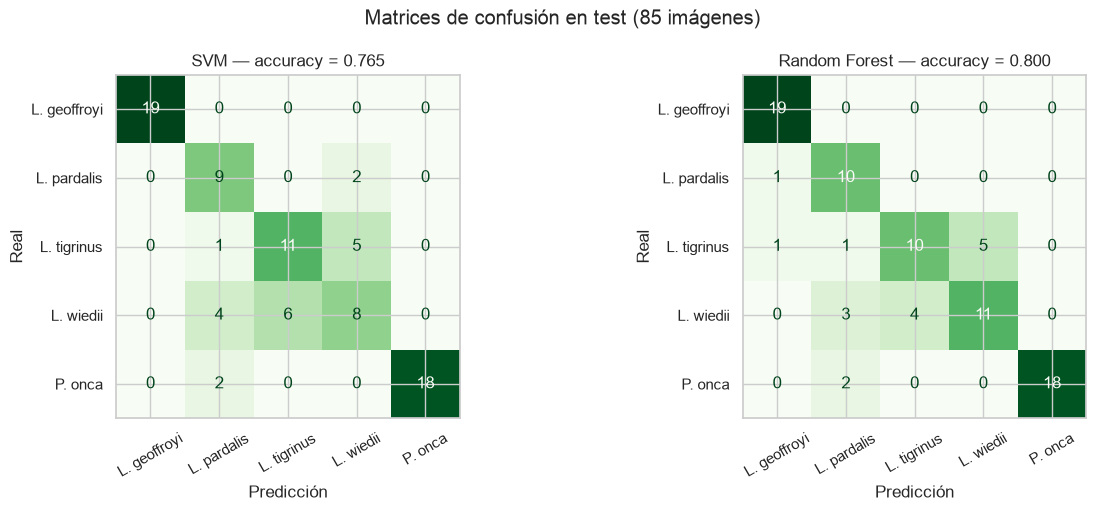

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
etiquetas = [NOMBRES[c] for c in CLASES]
for ax, nombre in zip(axes, MODELOS):
    cm = confusion_matrix(y_test, pred_test[nombre])
    ConfusionMatrixDisplay(cm, display_labels=etiquetas).plot(ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(f"{nombre} — accuracy = {accuracy_score(y_test, pred_test[nombre]):.3f}")
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    ax.tick_params(axis="x", rotation=30)
plt.suptitle("Matrices de confusión en test (85 imágenes)")
plt.tight_layout()
plt.savefig(FIG_DIR / "test_matrices_confusion.png", dpi=150)
plt.show()

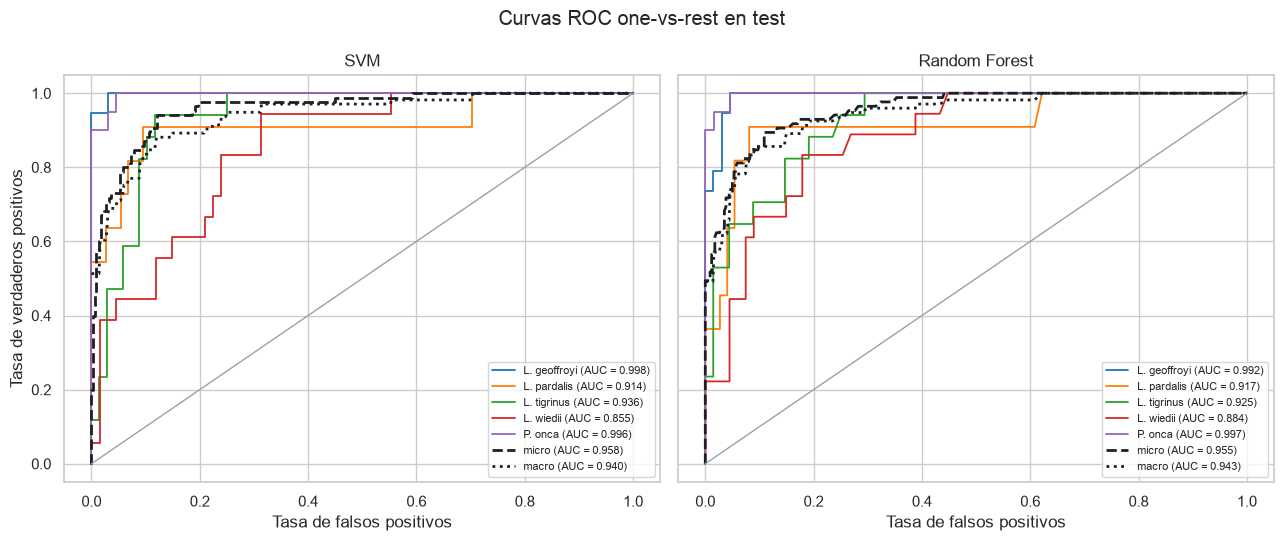

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, nombre in zip(axes, MODELOS):
    P = proba_test[nombre]
    tprs = []
    for i, c in enumerate(CLASES):
        fpr, tpr, _ = roc_curve(Y_test[:, i], P[:, i])
        tprs.append(np.interp(grid_fpr, fpr, tpr))
        ax.plot(fpr, tpr, color=colores[i], lw=1.3, label=f"{NOMBRES[c]} (AUC = {auc(fpr, tpr):.3f})")
    fpr, tpr, _ = roc_curve(Y_test.ravel(), P.ravel())
    ax.plot(fpr, tpr, color="#1d1f24", ls="--", lw=2, label=f"micro (AUC = {auc(fpr, tpr):.3f})")
    macro = np.mean(tprs, axis=0)
    ax.plot(grid_fpr, macro, color="#1d1f24", ls=":", lw=2, label=f"macro (AUC = {auc(grid_fpr, macro):.3f})")
    ax.plot([0, 1], [0, 1], color="#9aa0aa", lw=1)
    ax.set_title(nombre); ax.set_xlabel("Tasa de falsos positivos")
    ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("Tasa de verdaderos positivos")
plt.suptitle("Curvas ROC one-vs-rest en test")
plt.tight_layout()
plt.savefig(FIG_DIR / "test_roc.png", dpi=150)
plt.show()

### 9.0 ¿Es significativa la diferencia en test?

En test el orden de los modelos podría no coincidir con el del CV. Con 85 imágenes, unas pocas fotos cambian el resultado. Para comparar dos clasificadores sobre **el mismo** conjunto de test se usa el **test de McNemar** [14] (exacto, binomial), recomendado para este caso por Dietterich [15]: solo cuentan las imágenes en las que un modelo acierta y el otro falla.

In [30]:

ok_svm = pred_test["SVM"] == y_test
ok_rf = pred_test["Random Forest"] == y_test
b = int((ok_svm & ~ok_rf).sum())   # acierta SVM, falla RF
c = int((~ok_svm & ok_rf).sum())   # falla SVM, acierta RF
p_mcnemar = stats.binomtest(min(b, c), b + c, 0.5).pvalue if b + c > 0 else 1.0
print(f"Aciertos en test: SVM {ok_svm.sum()}/85, RF {ok_rf.sum()}/85")
print(f"Solo SVM acierta: {b} | solo RF acierta: {c} | ambos aciertan: {int((ok_svm & ok_rf).sum())} | ambos fallan: {int((~ok_svm & ~ok_rf).sum())}")
print(f"McNemar exacto: p = {p_mcnemar:.3f} → {'diferencia significativa' if p_mcnemar < ALFA else 'diferencia NO significativa'} (α = {ALFA})")


Aciertos en test: SVM 65/85, RF 68/85
Solo SVM acierta: 4 | solo RF acierta: 7 | ambos aciertan: 61 | ambos fallan: 13
McNemar exacto: p = 0.549 → diferencia NO significativa (α = 0.05)


### 9.1 ¿Influyen las fotos infrarrojas?

En el EDA se vio que el 32 % de las fotos son infrarrojas (efectivamente grises), concentradas en *L. pardalis* y *L. wiedii*. Se compara el acierto del SVM en fotos a color e infrarrojas, en test y en las predicciones de validación cruzada del conjunto de desarrollo (más imágenes, estimación más estable).

In [31]:
gris_test = df.loc[~es_dev, "es_gris"].to_numpy()
gris_dev = df.loc[es_dev, "es_gris"].to_numpy()
pred_cv_svm = proba["SVM"].argmax(axis=1)

filas = []
for conjunto, gris, real, pred in [("test", gris_test, y_test, pred_test["SVM"]),
                                    ("desarrollo (CV 10-fold)", gris_dev, y_dev, pred_cv_svm)]:
    for tipo, m in [("color", ~gris), ("infrarroja", gris)]:
        filas.append({"conjunto": conjunto, "tipo de foto": tipo, "imágenes": int(m.sum()),
                      "accuracy SVM": accuracy_score(real[m], pred[m])})
display(pd.DataFrame(filas).set_index(["conjunto", "tipo de foto"]).round(3))

# Qué especies predice el SVM para las fotos infrarrojas (CV en desarrollo)
display(pd.crosstab(pd.Series([NOMBRES[CLASES[i]] for i in y_dev[gris_dev]], name="real"),
                    pd.Series([NOMBRES[CLASES[i]] for i in pred_cv_svm[gris_dev]], name="predicción (infrarrojas)")))

imágenes  accuracy SVM
conjunto                tipo de foto                        
test                    color               51         0.804
                        infrarroja          34         0.706
desarrollo (CV 10-fold) color              525         0.827
                        infrarroja         240         0.675

predicción (infrarrojas),L. geoffroyi,L. pardalis,L. tigrinus,L. wiedii,P. onca
real,,,,,
L. geoffroyi,18,5,3,4,0
L. pardalis,8,57,3,9,2
L. tigrinus,3,5,19,9,0
L. wiedii,3,10,9,50,0
P. onca,0,4,0,1,18


### 9.2 Conclusiones de la evaluación final

| Métrica | SVM (test) | RF (test) | SVM (CV 10×10) |
| --- | --- | --- | --- |
| Accuracy | 0.765 | 0.800 | 0.775 |
| F1 macro | 0.749 | 0.786 | 0.775 |
| AUC macro / micro | 0.940 / 0.958 | 0.943 / 0.955 | 0.949 / 0.956 |

1. **En test el Random Forest queda por encima del SVM**, al revés que en el CV. Pero la diferencia son **3 imágenes** (65 vs. 68 aciertos de 85): los modelos solo discrepan en 11 fotos (7 a favor del RF, 4 a favor del SVM) y el **test de McNemar no la considera significativa (p = 0.55)**. Con 85 imágenes el test es demasiado chico para distinguir modelos que difieren en ~6 puntos; la evidencia fuerte sigue siendo el CV (100 folds, Wilcoxon p ≈ 10⁻¹⁷).
2. **El rendimiento del SVM en test (F1 0.749) es coherente con el CV (0.775)**, dentro de una desviación estándar: no hay señales de sobreajuste en la selección de hiperparámetros.
3. **Por especie:** *L. geoffroyi* (F1 = 1.0) y *P. onca* (0.95) se reconocen casi perfecto. Los errores se concentran en el trío de pelaje parecido: *L. wiedii* se confunde con *L. tigrinus* y *L. pardalis*, y *L. tigrinus* con *L. wiedii*.
4. **Fotos infrarrojas:** el SVM acierta el **82.7 %** de las fotos a color y solo el **67.5 %** de las infrarrojas (CV en desarrollo; en test, 80.4 % vs. 70.6 %). Sin color, el modelo depende solo del patrón de manchas, que en fotos nocturnas suele verse borroso.


## 10. Visualización con t-SNE

t-SNE [16] proyecta el espacio de características a 2 dimensiones intentando conservar qué puntos son vecinos. Se aplica a los **embeddings de la ResNet50** de las 850 imágenes, coloreando cada punto por su especie. Antes se reduce a 50 dimensiones con PCA (práctica estándar para acelerar t-SNE y reducir ruido).

Como contraste se aplica lo mismo a los **píxeles crudos** (imagen reducida a 64×64), para ver qué aporta el transfer learning. t-SNE depende de la *perplexity* (aprox. el número de vecinos que considera), así que se prueban 3 valores.

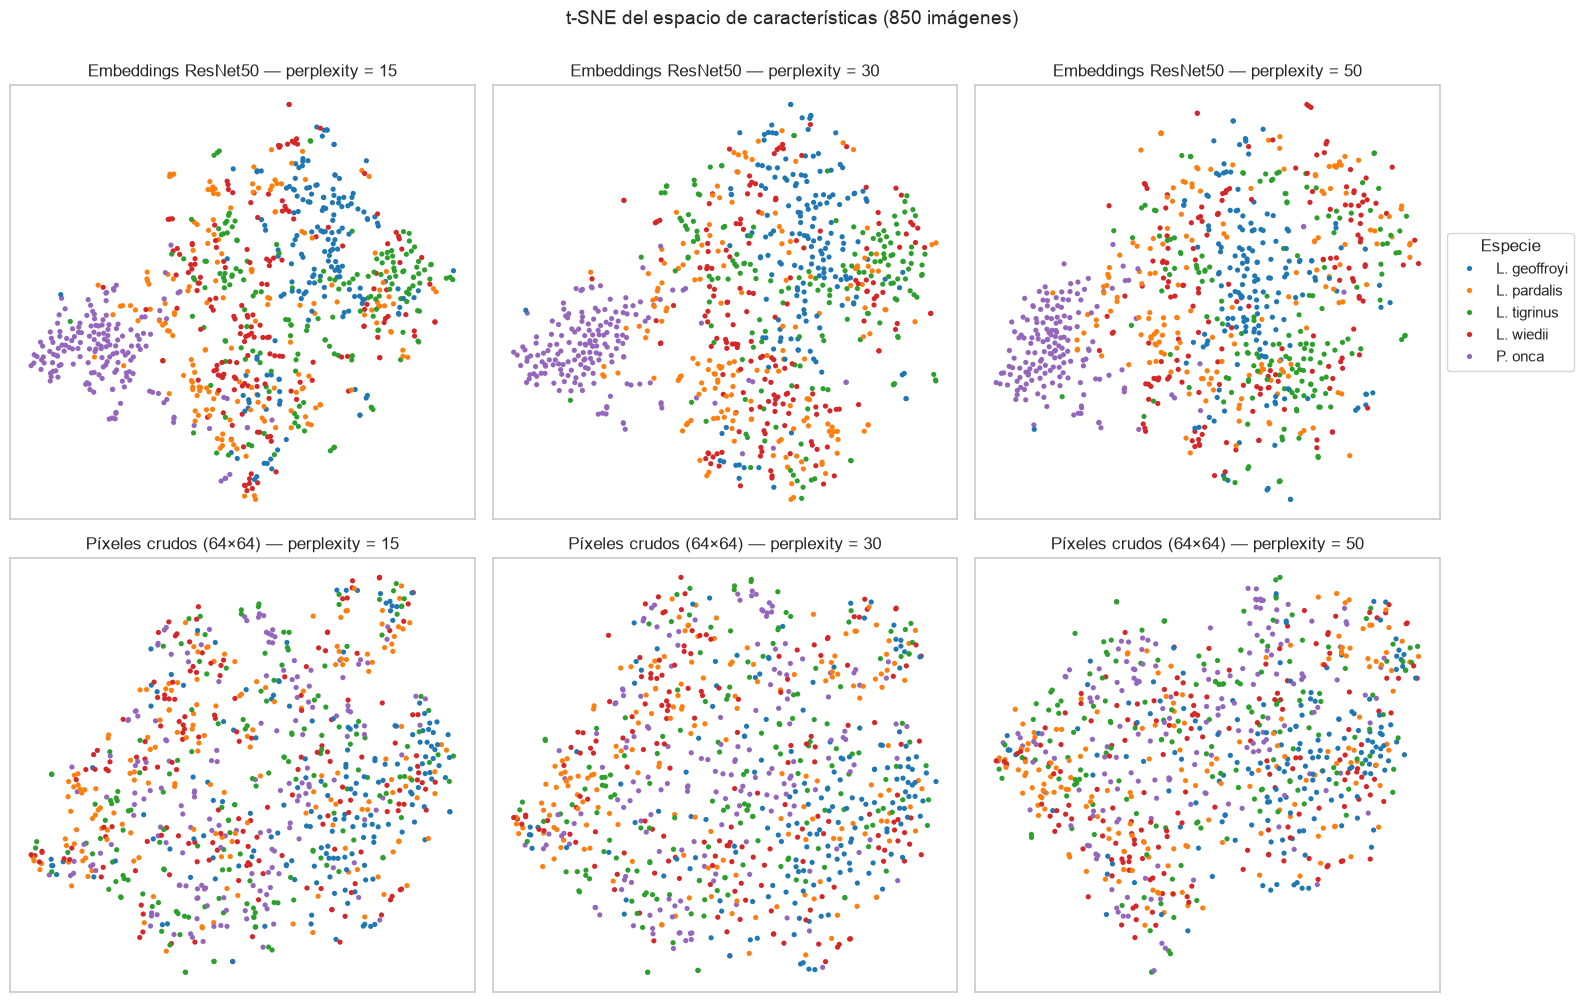

In [32]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

def tsne_2d(X, perplexity, nombre):
    archivo = EMB_DIR / f"tsne_{nombre}_p{perplexity}.npy"
    if archivo.exists():
        return np.load(archivo)
    Z = PCA(n_components=50, random_state=SEED).fit_transform(StandardScaler().fit_transform(X))
    Z = TSNE(n_components=2, perplexity=perplexity, init="pca", random_state=SEED).fit_transform(Z)
    np.save(archivo, Z)
    return Z

X_pix = np.stack([arreglo(r, 64).ravel() for r in df["ruta"]])  # píxeles crudos 64×64×3
especie = df["especie"].map(NOMBRES).to_numpy()
orden = [NOMBRES[c] for c in CLASES]
PERPLEXITIES = [15, 30, 50]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for fila, (X, nombre, titulo) in enumerate([(X_todo, "resnet", "Embeddings ResNet50"),
                                             (X_pix, "pixeles", "Píxeles crudos (64×64)")]):
    for col, perp in enumerate(PERPLEXITIES):
        Z = tsne_2d(X, perp, nombre)
        ax = axes[fila, col]
        sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=especie, hue_order=orden, palette="tab10",
                        s=14, linewidth=0, ax=ax, legend=(fila == 0 and col == 2))
        ax.set_title(f"{titulo} — perplexity = {perp}")
        ax.set_xticks([]); ax.set_yticks([])
axes[0, 2].legend(loc="center left", bbox_to_anchor=(1, 0.5), title="Especie")
plt.suptitle("t-SNE del espacio de características (850 imágenes)", y=1.0, fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "tsne_resnet_vs_pixeles.png", dpi=150, bbox_inches="tight")
plt.show()

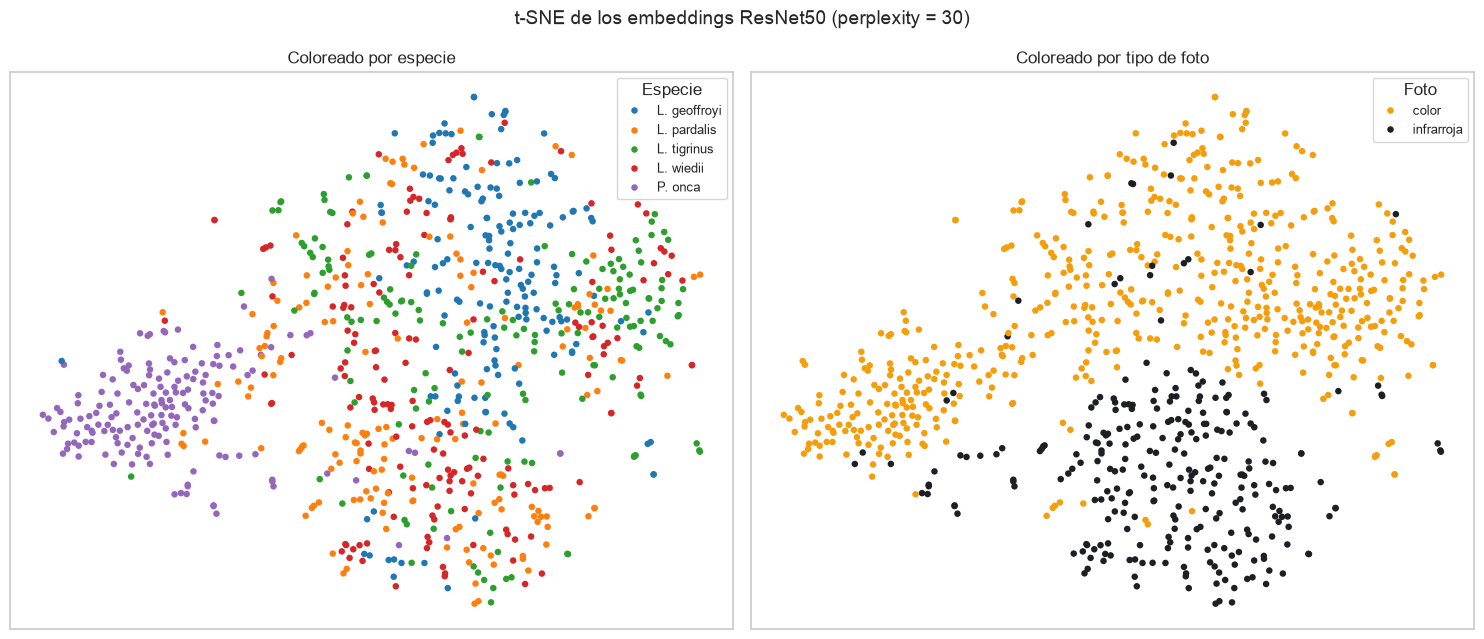

In [33]:
# Versión principal (perplexity 30) a mayor tamaño, y la misma proyección coloreada por tipo de foto
Z = tsne_2d(X_todo, 30, "resnet")
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=especie, hue_order=orden, palette="tab10", s=22,
                linewidth=0, ax=axes[0])
axes[0].set_title("Coloreado por especie")
axes[0].legend(title="Especie", fontsize=9)
tipo = np.where(df["es_gris"], "infrarroja", "color")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=tipo, hue_order=["color", "infrarroja"],
                palette=["#f59e0b", "#1d1f24"], s=22, linewidth=0, ax=axes[1])
axes[1].set_title("Coloreado por tipo de foto")
axes[1].legend(title="Foto", fontsize=9)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("t-SNE de los embeddings ResNet50 (perplexity = 30)", fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "tsne_resnet_especie_y_tipo.png", dpi=150)
plt.show()

### 10.1 Conclusiones del t-SNE

1. **El transfer learning organiza el espacio; los píxeles crudos no.** Con los embeddings de la ResNet50 aparecen grupos claros; con los píxeles crudos las especies quedan totalmente mezcladas en las tres perplexities. Esto justifica usar transfer learning en lugar de la opción clásica de píxeles + PCA.
2. ***P. onca* forma un grupo separado** del resto, lo que coincide con su AUC de 0.995 y su F1 de 0.95 en test. *L. geoffroyi* y *L. tigrinus* también forman zonas reconocibles.
3. ***L. wiedii* y *L. pardalis* están dispersas y mezcladas**, coherente con ser las especies más confundidas en la matriz de confusión.
4. **Hallazgo clave: el eje principal del espacio es el tipo de foto, no la especie.** Coloreando por tipo de foto, las infrarrojas forman su propia "isla" (abajo), y dentro de ella las especies se mezclan. La ResNet50 (entrenada con fotos diurnas de ImageNet) separa primero "día/noche" y después la especie. Esto explica por qué el acierto cae en fotos infrarrojas y por qué *pardalis* y *wiedii* (~50 % infrarrojas) son las más difíciles.
5. Los patrones se mantienen con perplexity 15, 30 y 50, así que no son un artefacto de ese parámetro.


## 11. Experimento extra: ¿importa el color?

**Pregunta:** ¿el color ayuda a distinguir las especies, o basta con la forma y el patrón de manchas?

**Diseño controlado (solo cambia el color):**
- **Versión gris = v2 convertida en código** (`Grayscale` replicado a 3 canales antes de la ResNet50). Mismas 850 fotos, mismos splits, mismo pipeline.
- El SVM se **reoptimiza** con la misma grilla sobre los embeddings grises, para no favorecer al color con hiperparámetros ajustados para él.
- Ambas versiones se evalúan con el **mismo** CV 10×10 → 100 pares de scores. Test: Wilcoxon pareado (α = 0.05) + t corregido.
- Como el 32 % de las fotos ya son infrarrojas (grises), el efecto del color solo puede aparecer en las fotos a color. Por eso en cada fold se calcula el F1 **por separado** para fotos a color e infrarrojas.

In [34]:
X_gris_todo = embeddings("resnet50_gris", gris=True)
X_dev_gris, X_test_gris = X_gris_todo[es_dev], X_gris_todo[~es_dev]

# Reoptimización del SVM sobre los embeddings grises (misma grilla y desempate)
X_dev_color = X_dev
X_dev = X_dev_gris            # buscar() usa X_dev
res_svm_gris, mejor_svm_gris = buscar("svm_gris", pipeline(SVC(kernel="rbf", random_state=SEED)), grilla_svm,
                                      desempate=["C"])
X_dev = X_dev_color           # se restaura
print("Mejores hiperparámetros SVM (color):", mejor_svm)
print("Mejores hiperparámetros SVM (gris): ", mejor_svm_gris)
tabla_top(res_svm_gris, 3)

Mejores hiperparámetros SVM (color): {'C': 100.0, 'gamma': 0.0001}
Mejores hiperparámetros SVM (gris):  {'C': 10.0, 'gamma': 0.0001}


,C,gamma,mean_test_score,std_test_score
26,10.0,0.0001,0.7672,0.0416
32,100.0,0.0001,0.7659,0.0449
38,1000.0,0.0001,0.7659,0.0449


In [35]:
from joblib import Parallel, delayed

def evaluar_fold(tr, va, Xa, pa, Xb, pb):
    """Entrena las dos versiones en el mismo fold y devuelve F1 macro total, en fotos a color y en infrarrojas."""
    out = {}
    gris_va = gris_dev[va]
    for nombre, X, params in [("color", Xa, pa), ("gris", Xb, pb)]:
        m = pipeline(SVC(kernel="rbf", random_state=SEED, **params)).fit(X[tr], y_dev[tr])
        yp = m.predict(X[va])
        out[f"{nombre}_total"] = f1_score(y_dev[va], yp, average="macro")
        out[f"{nombre}_fotos_color"] = f1_score(y_dev[va][~gris_va], yp[~gris_va], average="macro")
        out[f"{nombre}_fotos_ir"] = f1_score(y_dev[va][gris_va], yp[gris_va], average="macro")
    return out

archivo_color = CV_DIR / "color_vs_gris_10x10.csv"
if archivo_color.exists():
    cg = pd.read_csv(archivo_color)
else:
    t0 = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        cg = pd.DataFrame(Parallel(n_jobs=-1)(
            delayed(evaluar_fold)(tr, va, X_dev_color, mejor_svm, X_dev_gris, mejor_svm_gris)
            for tr, va in CV.split(X_dev_color, y_dev)))
    cg.to_csv(archivo_color, index=False)
    print(f"Color vs. gris: 100 folds en {(time.time() - t0) / 60:.1f} min")

filas = []
for sub, etiqueta in [("total", "todas las fotos"), ("fotos_color", "solo fotos a color"), ("fotos_ir", "solo fotos infrarrojas")]:
    a, b = cg[f"color_{sub}"], cg[f"gris_{sub}"]
    d = (a - b).to_numpy()
    filas.append({"subconjunto": etiqueta, "F1 color": f"{a.mean():.3f} ± {a.std():.3f}",
                  "F1 gris": f"{b.mean():.3f} ± {b.std():.3f}", "color − gris": d.mean(),
                  "folds gana color": int((d > 0).sum()), "Wilcoxon p": stats.wilcoxon(a, b).pvalue,
                  "t corregido p": t_corregido(d, n_train_fold, n_test_fold)[1]})
res_cg = pd.DataFrame(filas).set_index("subconjunto")
res_cg.style.format({"color − gris": "{:+.3f}", "Wilcoxon p": "{:.2e}", "t corregido p": "{:.2e}"})

,F1 color,F1 gris,color − gris,folds gana color,Wilcoxon p,t corregido p
subconjunto,,,,,,
todas las fotos,0.775 ± 0.040,0.767 ± 0.042,+0.008,58,2.18e-02,5.37e-01
solo fotos a color,0.794 ± 0.050,0.768 ± 0.055,+0.026,69,1.65e-05,1.63e-01
solo fotos infrarrojas,0.650 ± 0.109,0.684 ± 0.112,-0.034,38,1.20e-03,3.08e-01


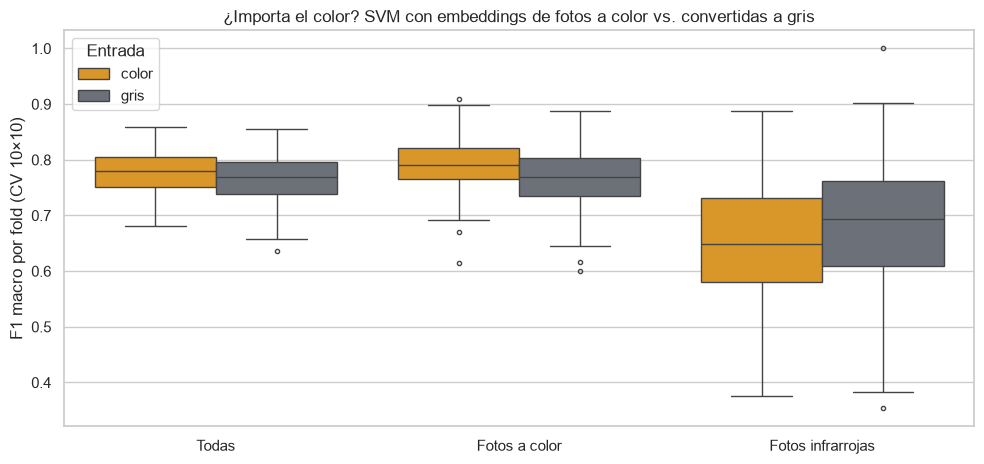

In [36]:
largo = pd.DataFrame({
    "subconjunto": np.repeat(["Todas", "Fotos a color", "Fotos infrarrojas"], 2 * len(cg)),
    "versión": np.tile(np.repeat(["color", "gris"], len(cg)), 3),
    "F1 macro": np.concatenate([cg["color_total"], cg["gris_total"], cg["color_fotos_color"],
                                cg["gris_fotos_color"], cg["color_fotos_ir"], cg["gris_fotos_ir"]]),
})
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.boxplot(data=largo, x="subconjunto", y="F1 macro", hue="versión", palette=["#f59e0b", "#6a6f7a"], ax=ax,
            flierprops={"marker": "o", "markersize": 3})
ax.set_xlabel("")
ax.set_ylabel("F1 macro por fold (CV 10×10)")
ax.set_title("¿Importa el color? SVM con embeddings de fotos a color vs. convertidas a gris")
ax.legend(title="Entrada")
plt.tight_layout()
plt.savefig(FIG_DIR / "color_vs_gris.png", dpi=150)
plt.show()

In [37]:
# F1 por especie (predicciones de un 10-fold, solo fotos a color, donde el color puede influir)
cv1 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    pred_c = cross_val_predict(pipeline(SVC(kernel="rbf", random_state=SEED, **mejor_svm)), X_dev_color, y_dev, cv=cv1, n_jobs=-1)
    pred_g = cross_val_predict(pipeline(SVC(kernel="rbf", random_state=SEED, **mejor_svm_gris)), X_dev_gris, y_dev, cv=cv1, n_jobs=-1)
m = ~gris_dev
por_especie = pd.DataFrame({
    "F1 color": f1_score(y_dev[m], pred_c[m], average=None),
    "F1 gris": f1_score(y_dev[m], pred_g[m], average=None),
}, index=[NOMBRES[c] for c in CLASES])
por_especie["color − gris"] = por_especie["F1 color"] - por_especie["F1 gris"]
por_especie.round(3)

,F1 color,F1 gris,color − gris
L. geoffroyi,0.904,0.860,0.044
L. pardalis,0.688,0.722,-0.034
L. tigrinus,0.777,0.715,0.062
L. wiedii,0.691,0.601,0.090
P. onca,0.972,0.976,-0.004


### 11.1 Chequeo secundario: la exportación gris de Roboflow

Roboflow también exportó las mismas fotos en gris (carpeta `classificador_imagem_segmentada`, que pese al nombre conserva el fondo). Se emparejan con v2 por número de archivo y especie, y se comparan las tres entradas (color, gris en código, gris de Roboflow) sobre las fotos de desarrollo presentes en ambas versiones, con un mismo CV 10×10.

In [38]:
ZIP_SEG = RAIZ / "zips" / "classificador_imagem_segmentada.v1i.multiclass.zip"
SEG_DIR = RAIZ / "data" / "segmentada"
if not (SEG_DIR / "train" / "_classes.csv").exists():
    with zipfile.ZipFile(ZIP_SEG) as z:
        z.extractall(SEG_DIR)

def clave(ruta, especie):
    return (Path(ruta).name.split("_")[0], especie)

seg = []
for s in ["train", "valid", "test"]:
    d = pd.read_csv(SEG_DIR / s / "_classes.csv"); d.columns = [c.strip() for c in d.columns]
    for f, i in zip(d["filename"], d[CLASES].to_numpy().argmax(axis=1)):
        seg.append({"ruta_seg": str(SEG_DIR / s / f.strip()), "especie": CLASES[i]})
seg = pd.DataFrame(seg)
seg["clave"] = [clave(r, e) for r, e in zip(seg["ruta_seg"], seg["especie"])]
mapa_seg = dict(zip(seg["clave"], seg["ruta_seg"]))

dev_df = df[es_dev].reset_index(drop=True)
dev_df["ruta_seg"] = [mapa_seg.get(clave(r, e)) for r, e in zip(dev_df["ruta"], dev_df["especie"])]
comun = dev_df["ruta_seg"].notna().to_numpy()
print(f"Fotos de desarrollo con par en la exportación de Roboflow: {comun.sum()} de {len(dev_df)}")

archivo_seg = EMB_DIR / "resnet50_roboflow_gris_dev.npy"
if archivo_seg.exists():
    X_seg = np.load(archivo_seg)
else:
    X_seg = extraer(resnet50_extractor(), dev_df.loc[comun, "ruta_seg"], transformacion(gris=False))
    np.save(archivo_seg, X_seg)

Xc, Xg, ys = X_dev_color[comun], X_dev_gris[comun], y_dev[comun]
CV_SEG = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=SEED)
versiones = {"color": (Xc, mejor_svm), "gris (código)": (Xg, mejor_svm_gris), "gris (Roboflow)": (X_seg, mejor_svm_gris)}

archivo_cmp_seg = CV_DIR / "color_vs_gris_roboflow_10x10.csv"
if archivo_cmp_seg.exists():
    sc = pd.read_csv(archivo_cmp_seg)
else:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sc = pd.DataFrame({n: cross_val_score(pipeline(SVC(kernel="rbf", random_state=SEED, **p)), X, ys,
                                              cv=CV_SEG, scoring=METRICA, n_jobs=-1)
                           for n, (X, p) in versiones.items()})
    sc.to_csv(archivo_cmp_seg, index=False)

display(sc.agg(["mean", "std"]).T.round(3))
print("Wilcoxon gris (código) vs. gris (Roboflow): p =", f"{stats.wilcoxon(sc['gris (código)'], sc['gris (Roboflow)']).pvalue:.3g}")
print("Wilcoxon color vs. gris (Roboflow):         p =", f"{stats.wilcoxon(sc['color'], sc['gris (Roboflow)']).pvalue:.3g}")

Fotos de desarrollo con par en la exportación de Roboflow: 720 de 765


,mean,std
color,0.768,0.040
gris (código),0.771,0.041
gris (Roboflow),0.763,0.042


Wilcoxon gris (código) vs. gris (Roboflow): p = 0.0097
Wilcoxon color vs. gris (Roboflow):         p = 0.218


### 11.2 Conclusiones del experimento

| Subconjunto (CV 10×10) | F1 color | F1 gris | Color − gris | Wilcoxon p | t corregido p |
| --- | --- | --- | --- | --- | --- |
| Todas las fotos | 0.775 | 0.767 | **+0.008** | 0.022 | 0.54 |
| Solo fotos a color | 0.794 | 0.768 | **+0.026** | 1.7 × 10⁻⁵ | 0.16 |
| Solo fotos infrarrojas | 0.650 | 0.684 | **−0.034** | 0.0012 | 0.31 |

1. **El color aporta poco en total:** +0.008 de F1 macro. El Wilcoxon lo marca como significativo (p = 0.02), pero el t-test corregido no (p = 0.54). Como el Wilcoxon sobre folds solapados es optimista, la conclusión prudente es que **el efecto global es mínimo y no robusto**. La forma y el patrón de manchas son la información principal.
2. **En fotos a color, el color sí ayuda** (+0.026; el modelo a color gana en 69 de 100 folds). Las especies que más ganan son *L. wiedii* (+0.09), *L. tigrinus* (+0.06) y *L. geoffroyi* (+0.04); *P. onca* no cambia (ya se reconoce por su patrón de rosetas).
3. **En fotos infrarrojas, convertir todo a gris mejora** (−0.034 para el color). Con todo en gris, las fotos diurnas y nocturnas se parecen más y el modelo puede aprender un solo patrón. Con color, las infrarrojas quedan como un grupo aparte con pocos ejemplos (ver el t-SNE). Ninguna de estas diferencias por subconjunto es significativa con el t corregido.
4. **Chequeo con la exportación gris de Roboflow** (720 fotos en común): color 0.768, gris en código 0.771, gris de Roboflow 0.763. No hay diferencia relevante entre color y gris de Roboflow (p = 0.22). La pequeña diferencia entre las dos versiones grises (p = 0.01) se explica porque Roboflow usa otra fórmula de conversión ("CRT phosphor") y otra resolución.
5. **Conclusión práctica:** hay un compromiso. El color ayuda en fotos diurnas y estorba en las nocturnas, y en total casi se compensa. Un trabajo futuro sería tratar las fotos infrarrojas por separado o con aumentos de datos que conviertan aleatoriamente fotos a gris.


## 12. Conclusiones

1. **El transfer learning funciona con pocos datos.** Sin entrenar ninguna red, los embeddings de una ResNet50 preentrenada permiten clasificar 5 especies con un **F1 macro de 0.775** (SVM, CV 10×10) y un **AUC macro de 0.949**, frente a 0.20 del azar. En el t-SNE, los embeddings forman grupos por especie mientras que los píxeles crudos quedan mezclados.

2. **El SVM es el mejor modelo.** Supera al Random Forest en todas las métricas del CV (F1 macro 0.775 vs. 0.710) y gana en 93 de 100 folds. La diferencia es significativa con Wilcoxon (p ≈ 2 × 10⁻¹⁷) y también con el t-test corregido de Nadeau–Bengio (p ≈ 3 × 10⁻⁵), que compensa la dependencia entre folds. En el test de 85 imágenes el Random Forest acertó 3 fotos más, pero McNemar no encuentra diferencia significativa (p = 0.55): con un test tan chico no se puede distinguir entre modelos tan cercanos.

3. **La optimización importa, sobre todo en el SVM.** Ajustar `C` y `gamma` subió el F1 macro de 0.68 a 0.78. `gamma` es decisivo: con valores grandes el modelo colapsa a una sola clase. Optuna confirmó la región óptima encontrada por la grilla.

4. **Hay varianza alta: más datos ayudarían.** En las curvas de aprendizaje ambos modelos obtienen F1 = 1.0 en entrenamiento y la validación sigue subiendo al agregar imágenes.

5. **Las especies difíciles son las de pelaje parecido.** *P. onca* (AUC 0.995) y *L. geoffroyi* se reconocen casi sin errores; *L. wiedii*, *L. pardalis* y *L. tigrinus* concentran las confusiones.

6. **Las fotos nocturnas son el principal problema.** El 32 % del dataset son fotos infrarrojas, concentradas en *L. pardalis* y *L. wiedii*. En el t-SNE forman su propio grupo: la ResNet50 separa día/noche antes que la especie. El SVM acierta el 82.7 % de las fotos a color y solo el 67.5 % de las infrarrojas.

7. **El color aporta poco en total.** Pasar todas las fotos a gris baja el F1 apenas 0.008, una diferencia no robusta según el t corregido. El color ayuda en fotos diurnas (+0.026, sobre todo en *L. wiedii*) y empeora las nocturnas (−0.034). La información principal es el patrón de manchas.

### Limitaciones

- Dataset pequeño (850 fotos) y heterogéneo (cámaras trampa, zoológicos, animales atropellados, marcas de agua), con imágenes deformadas por el redimensionamiento de Roboflow.
- El test de 85 imágenes no tiene poder estadístico para comparar modelos cercanos.
- Las pruebas sobre folds de CV repetido no son independientes. Lo mitigamos con el t corregido, pero los p-valores del Wilcoxon son optimistas.
- La ResNet50 se usó como extractor fijo; no se hizo fine-tuning.

### Trabajo futuro

- Tratar las fotos infrarrojas de forma explícita: un modelo aparte, o *data augmentation* que pase fotos a gris al azar.
- Probar otros extractores preentrenados (CLIP, DINOv2) o hacer fine-tuning con aumentos de datos.
- Conseguir más fotos, sobre todo nocturnas de *L. wiedii*, *L. pardalis* y *L. tigrinus*.


## 13. Uso de IA generativa

El código y el texto de esta notebook se desarrollaron con asistencia de **Claude Code** (Anthropic), un asistente de programación basado en un modelo de lenguaje, y fueron revisados por el grupo. Las decisiones de diseño se discutieron con el asistente y están documentadas en el repositorio (`docs/decisiones-plan-a.md` y la bitácora `docs/bitacora.md`).

Prompts principales usados (textuales, en el orden en que se dieron):

1. *"check the plantilla md file and break into multiple mds as needed for us to work on this project"*
2. *"okay also crete a game plan A based on the pantilla adn just the classificador_felideos.v2i.multiclass"*
3. *"what if we compare the performance from v2 and segmented"* → *"yes I want to test this color vs grayscale"*
4. *"so we have this graph I need you to analyse and replicate it on html. as we need to follow that for the presentation"* (diagrama del pipeline visto en clase)
5. *"that recomended workflow works, yes set local env and start development"*
6. *"yes to both questions"* (continuar con la optimización de hiperparámetros)
7. *"is it running or you need you sign of?"* (continuar con las fases restantes del plan)


## 14. Referencias

[1] A. F. O'Connell, J. D. Nichols y K. U. Karanth, Eds., *Camera Traps in Animal Ecology: Methods and Analyses*. Tokio, Japón: Springer, 2011.

[2] M. S. Norouzzadeh *et al.*, "Automatically identifying, counting, and describing wild animals in camera-trap images with deep learning," *Proc. Natl. Acad. Sci. USA*, vol. 115, no. 25, pp. E5716–E5725, 2018.

[3] K. He, X. Zhang, S. Ren y J. Sun, "Deep residual learning for image recognition," en *Proc. IEEE Conf. Comput. Vis. Pattern Recognit. (CVPR)*, 2016, pp. 770–778.

[4] J. Deng, W. Dong, R. Socher, L.-J. Li, K. Li y L. Fei-Fei, "ImageNet: A large-scale hierarchical image database," en *Proc. IEEE Conf. Comput. Vis. Pattern Recognit. (CVPR)*, 2009, pp. 248–255.

[5] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.

[6] C. Cortes y V. Vapnik, "Support-vector networks," *Mach. Learn.*, vol. 20, no. 3, pp. 273–297, 1995.

[7] L. Breiman, "Random forests," *Mach. Learn.*, vol. 45, no. 1, pp. 5–32, 2001.

[8] F. Wilcoxon, "Individual comparisons by ranking methods," *Biometrics Bull.*, vol. 1, no. 6, pp. 80–83, 1945.

[9] A. Paszke *et al.*, "PyTorch: An imperative style, high-performance deep learning library," en *Adv. Neural Inf. Process. Syst. (NeurIPS)*, vol. 32, 2019, pp. 8024–8035.

[10] W. Colombo, "classificador_felideos," Roboflow Universe, versión 2, jun. 2024. [En línea]. Disponible: https://universe.roboflow.com/willian-colombo/classificador_felideos. Licencia CC BY 4.0.

[11] T. Akiba, S. Sano, T. Yanase, T. Ohta y M. Koyama, "Optuna: A next-generation hyperparameter optimization framework," en *Proc. 25th ACM SIGKDD Int. Conf. Knowl. Discov. Data Min.*, 2019, pp. 2623–2631.

[12] S. S. Shapiro y M. B. Wilk, "An analysis of variance test for normality (complete samples)," *Biometrika*, vol. 52, no. 3–4, pp. 591–611, 1965.

[13] C. Nadeau y Y. Bengio, "Inference for the generalization error," *Mach. Learn.*, vol. 52, no. 3, pp. 239–281, 2003.

[14] Q. McNemar, "Note on the sampling error of the difference between correlated proportions or percentages," *Psychometrika*, vol. 12, no. 2, pp. 153–157, 1947.

[15] T. G. Dietterich, "Approximate statistical tests for comparing supervised classification learning algorithms," *Neural Comput.*, vol. 10, no. 7, pp. 1895–1923, 1998.

[16] L. van der Maaten y G. Hinton, "Visualizing data using t-SNE," *J. Mach. Learn. Res.*, vol. 9, pp. 2579–2605, 2008.
